# Swin-UNet Fetal Head Segmentation + HC Pipeline
This notebook implements a strong Swin-UNet segmentation pipeline using filled masks, Dice+BCE loss, and ellipse-based HC estimation.

## Model comparison extension: Standard U-Net vs Attention U-Net vs Swin-UNet

**Everything above the "Model comparison" section at the end is the original pipeline.** Cells added by this extension are marked **`[ADDED]`** in their first line (or title). Only three original cells were touched (see the change log below).

**Protocol.** All three models use the same `train_loader` / `val_loader` (same images, same 80/20 split with `RandomState(42)`, same augmentation and normalisation), the same loss (0.3·BCE + 0.5·Dice + 0.2·boundary), optimiser (Adam, `LR`), scheduler (ReduceLROnPlateau on val Dice), `EPOCHS`, batch size, and best-val-Dice checkpointing. Each model has its own optimiser, scheduler, checkpoint file and history. Swin-UNet is trained by the **original** training cell; the two baselines by an added function that mirrors that cell line-for-line. Results are produced only by running the notebook. Anything not yet run is shown as **PENDING**.

**Architecture-specific difference (kept intentionally).** The original Swin-UNet freezes its *pretrained* encoder for the first `FREEZE_EPOCHS` epochs. The two U-Nets are trained from scratch, so there is nothing pretrained to freeze and they train all weights from epoch 1.

### Change log (edits to original cells)
| # | Original cell | Edit | Why |
|---|---|---|---|
| 1 | Training cell (Swin-UNet) | Added `swin_history = []` and one `swin_history.append(...)` per epoch | Records Swin-UNet's per-epoch losses/metrics for the comparison plots. Instrumentation only. Training behaviour is unchanged. |
| 2 | Checkpoint-load cell | `"model.pth"` → `"best_model.pth"` | **Essential fix.** The training cell saves `best_model.pth`; nothing ever writes `model.pth`, so a fresh run raised `FileNotFoundError`. (The saved output of this cell in your notebook shows `best_model.pth` was used when it last ran.) |
| 3 | *(new cell before the HC-evaluation cell)* | Defines `best_t = 0.5` | **Essential fix.** The HC-evaluation cell uses `best_t`, which is defined nowhere in the notebook, so it raised `NameError`. 0.5 is the threshold used everywhere else in the notebook. **If you had tuned a different threshold earlier, set it in that cell.** |

Added and unchanged-behaviour items, plus known caveats, are listed in the final cell of this notebook.

c:\Users\deepr\OneDrive\Desktop\rp1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded 799 train metadata rows and 200 validation images. No training will run.
Found optional history for Standard U-Net: history_standard_u-net.json
Evaluated Swin-UNet: Dice=0.9671, IoU=0.9392, inference=33.31 ms/image
Evaluated Standard U-Net: Dice=0.9646, IoU=0.9346, inference=43.00 ms/image
Evaluated Attention U-Net: Dice=0.9484, IoU=0.9062, inference=47.94 ms/image


,Model,Status,Params (M),Best epoch (history),Val Dice (batch-mean),Val IoU (batch-mean),Val Dice (per-image mean),Val IoU (per-image mean),"HC MAE [px, 256x256]","HC RMSE [px, 256x256]",HC MAE [mm vs CSV HC],HC RMSE [mm vs CSV HC],Inference [ms/image],Inference std [ms],N val images,N common samples (px HC),N common samples (mm HC),HC MAE [px] own-valid,HC RMSE [px] own-valid,N own-valid (px),HC MAE [mm] own-valid,HC RMSE [mm] own-valid,N own-valid (mm),Device
0,Swin-UNet,COMPLETE,34.395099,Not recorded,0.967059,0.939245,0.963968,0.939311,7.678087,9.430028,2.875225,3.662248,33.309604,13.079260,200,198,200,7.678087,9.430028,198,2.875225,3.662248,200,NVIDIA GeForce RTX 2050
1,Standard U-Net,COMPLETE,31.043521,15,0.964608,0.934625,0.960066,0.932695,9.230965,12.156074,3.202676,4.151708,43.000298,6.360778,200,198,200,9.230965,12.156074,198,3.202676,4.151708,200,NVIDIA GeForce RTX 2050
2,Attention U-Net,COMPLETE,31.395053,Not recorded,0.948402,0.906192,0.935085,0.894735,17.560856,43.874328,6.069539,13.276976,47.936396,0.965553,200,198,200,17.560856,43.874328,198,6.069539,13.276976,200,NVIDIA GeForce RTX 2050



Saved table: c:\Users\deepr\OneDrive\Desktop\rp1\comparison_results\comparison_summary.csv
Saved per-image results: c:\Users\deepr\OneDrive\Desktop\rp1\comparison_results\comparison_per_sample.csv


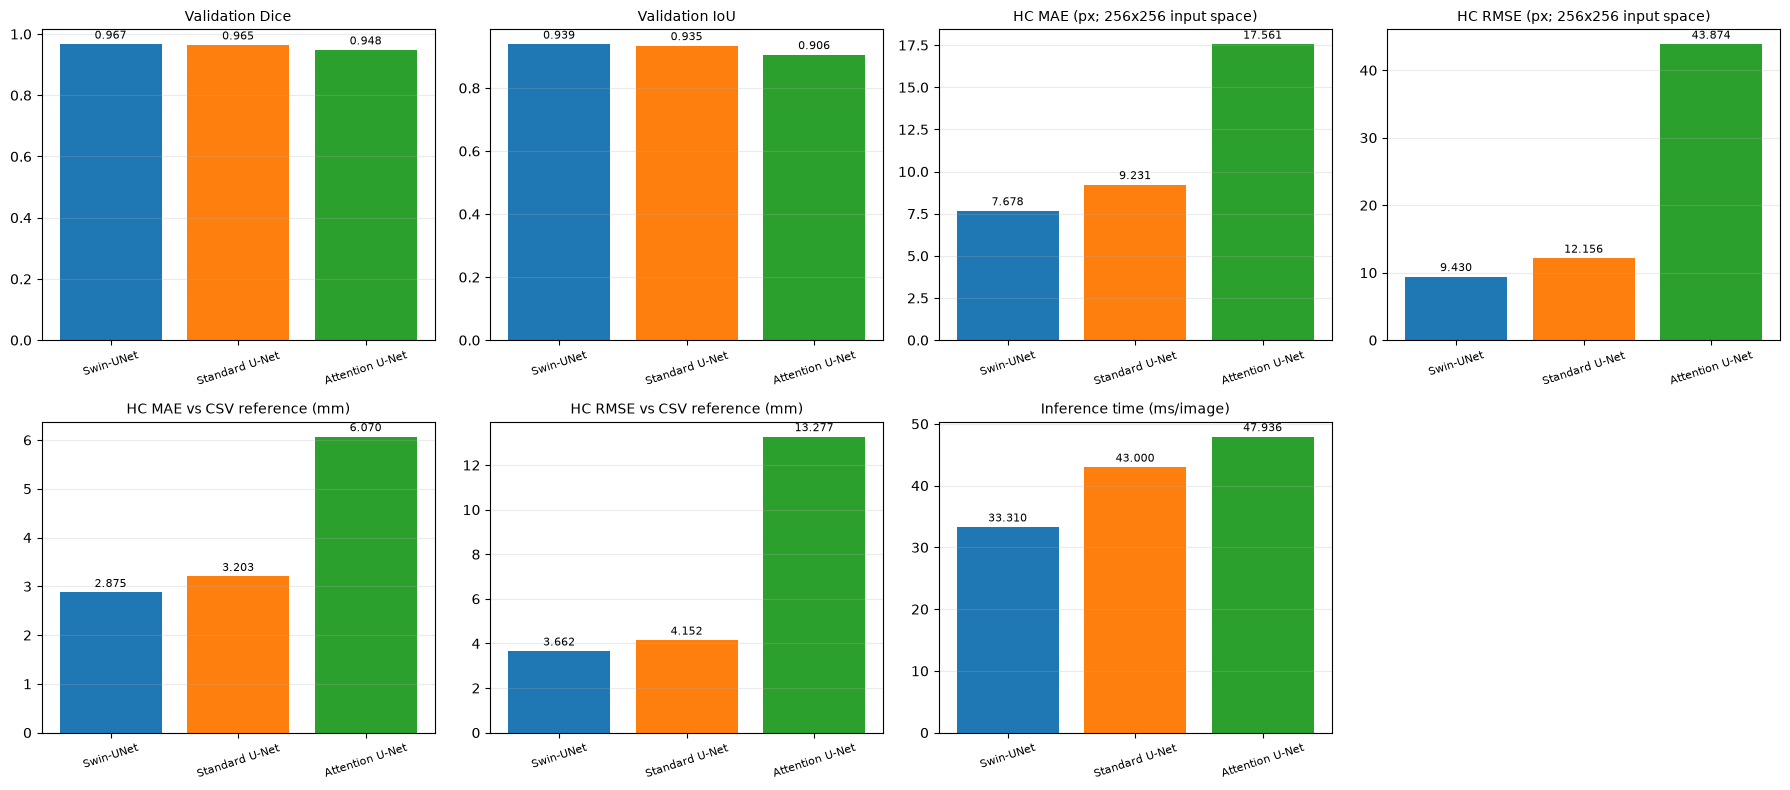

Saved comparison graph: c:\Users\deepr\OneDrive\Desktop\rp1\comparison_results\plot_model_metrics.png


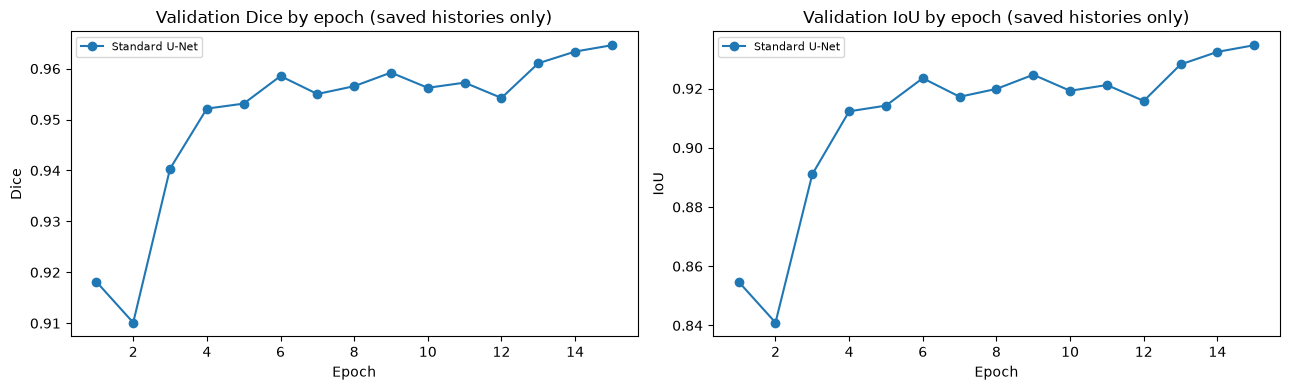

Saved optional history graph: c:\Users\deepr\OneDrive\Desktop\rp1\comparison_results\plot_saved_training_history.png

Finished. Evaluation only: no model training or optimizer steps were run.


In [1]:
"""Evaluate the saved fetal head segmentation models without training.

Run from the project directory that contains:
  training_set/ and training_set_pixel_size_and_HC.csv
  best_model.pth
  comparison_results/best_standard_unet.pth
  comparison_results/best_attention_unet.pth

Outputs are saved under comparison_results/. This script only loads checkpoints and evaluates them.
"""
from pathlib import Path
import os, time, json, math, copy, platform, random
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import timm
from torchvision.transforms import functional as TF
from torchvision import transforms
import matplotlib.pyplot as plt
import albumentations as A
from albumentations.pytorch import ToTensorV2

BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()

# ================= Imports =================
import os, math, cv2
import json
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import timm
from torchvision.transforms import functional as TF
from torchvision import transforms
import matplotlib.pyplot as plt
# albumentations for synchronized image+mask augmentations
import albumentations as A
from albumentations.pytorch import ToTensorV2

# ---- Canonical helpers (define once to override duplicates) ----
import math
def canonical_clean_mask(mask):
    mask = (mask > 0).astype(np.uint8)
    mask_blur = cv2.GaussianBlur(mask * 255, (7,7), 0)
    _, mask_bin = cv2.threshold(mask_blur, 127, 255, cv2.THRESH_BINARY)
    mask_bin = mask_bin // 255
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask_bin, 8)
    if num_labels <= 1:
        return None
    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    clean = (labels == largest_label).astype(np.uint8)
    contours, _ = cv2.findContours(clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(clean)
    cv2.drawContours(filled, contours, -1, 1, thickness=-1)
    return filled

def canonical_mask_to_ellipse(mask):
    mask = (mask > 0).astype(np.uint8) * 255
    mask = cv2.GaussianBlur(mask, (9, 9), 0)
    _, mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if len(contours) == 0:
        return None
    cnt = max(contours, key=cv2.contourArea)
    if len(cnt) < 5:
        return None
    ellipse = cv2.fitEllipse(cnt)
    return ellipse

def canonical_hc_from_ellipse(ellipse):
    (_, _), (MA, ma), _ = ellipse
    a = MA / 2.0
    b = ma / 2.0
    if a <= 0 or b <= 0:
        return None
    h = ((a - b) ** 2) / ((a + b) ** 2 + 1e-8)
    circ = math.pi * (a + b) * (1 + (3 * h) / (10 + math.sqrt(4 - 3 * h)))
    return circ

# Create simple wrappers with historical names so existing cells keep working
def clean_mask(mask):
    return canonical_clean_mask(mask)
def mask_to_ellipse(mask):
    return canonical_mask_to_ellipse(mask)
def hc_from_ellipse(ellipse):
    return canonical_hc_from_ellipse(ellipse)
def ellipse_and_hc(mask):
    ellipse = canonical_mask_to_ellipse(mask)
    if ellipse is None:
        return None, None
    return ellipse, canonical_hc_from_ellipse(ellipse)

IMG_SIZE = 256
BATCH_SIZE = 4
EPOCHS = 15         
LR = 5e-5          
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'


# ================= Mask Filling =================
def load_and_fill_mask(mask_path):
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    _, bin_mask = cv2.threshold(mask, 5, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(bin_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(bin_mask)
    cv2.drawContours(filled, contours, -1, 255, thickness=-1)
    return filled.astype(np.float32) / 255.0


class ResizeWithPad:
    def __init__(self, size=256):
        self.size = size

    def __call__(self, img):
        if not isinstance(img, Image.Image):
            img = TF.to_pil_image(img)

        w, h = img.size

        scale = self.size / max(w, h)
        new_w = int(w * scale)
        new_h = int(h * scale)

        img = TF.resize(img, (new_h, new_w))

        pad_w = self.size - new_w
        pad_h = self.size - new_h

        padding = (
            pad_w // 2,
            pad_h // 2,
            pad_w - pad_w // 2,
            pad_h - pad_h // 2
        )

        img = TF.pad(img, padding, fill=0)
        return img


img_tfms = transforms.Compose([
    ResizeWithPad(256),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ---------- Mask transforms ----------
mask_tfms = transforms.Compose([
    ResizeWithPad(256),
    transforms.ToTensor()
])

class TrainDataset(Dataset):
    def __init__(self, img_dir, csv_path, indices=None, augmentations=None):
        self.img_dir = img_dir
        self.df = pd.read_csv(csv_path)
        if indices is not None:
            self.df = self.df.iloc[indices].reset_index(drop=True)
        self.augmentations = augmentations

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        img_path = os.path.join(self.img_dir, row["filename"])
        mask_path = img_path.replace(".png", "_Annotation.png")

        img = Image.open(img_path).convert("RGB")
        filled = load_and_fill_mask(mask_path)
        mask_np = (filled * 255).astype(np.uint8)
        img_np = np.array(img)

        # ---- apply synchronized augmentations (albumentations) if provided ----
        if self.augmentations is not None:
            aug = self.augmentations(image=img_np, mask=mask_np)
            img_np = aug['image']
            mask_np = aug['mask']
        else:
            # fallback: resize+pad using existing transforms
            img = Image.fromarray(img_np)
            img = img_tfms(img)
            mask = Image.fromarray(mask_np)
            mask = mask_tfms(mask)
            mask = (mask > 0).float()
            hc = torch.tensor(row["head circumference (mm)"], dtype=torch.float32)
            pixel_size = torch.tensor(row["pixel size(mm)"], dtype=torch.float32)
            # orig sizes
            orig_h, orig_w = img_np.shape[0], img_np.shape[1]
            return img, mask, hc, pixel_size, orig_w, orig_h

        # ---- numpy -> tensor (channels-first) and normalize using torchvision stats ----
        img_tensor = transforms.ToTensor()(img_np)
        img_tensor = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229,0.224,0.225])(img_tensor)
        mask_tensor = torch.from_numpy((mask_np > 127).astype(np.float32)).unsqueeze(0)

        hc = torch.tensor(row["head circumference (mm)"], dtype=torch.float32)
        pixel_size = torch.tensor(row["pixel size(mm)"], dtype=torch.float32)
        orig_h, orig_w = img_np.shape[0], img_np.shape[1]

        return img_tensor, mask_tensor, hc, pixel_size, orig_w, orig_h



class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)



# ================= Swin-UNet =================
class SwinUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = timm.create_model(
            'swin_tiny_patch4_window7_224',
            pretrained=False,
            features_only=True,
            img_size=256
        )

        ch = self.encoder.feature_info.channels()
        # ch = [96, 192, 384, 768] typically

        # ---------- Upsampling ----------
        self.up4 = nn.ConvTranspose2d(ch[3], ch[2], 2, 2)
        self.up3 = nn.ConvTranspose2d(ch[2], ch[1], 2, 2)
        self.up2 = nn.ConvTranspose2d(ch[1], ch[0], 2, 2)
        self.up1 = nn.ConvTranspose2d(ch[0], 64, 2, 2)

        # ---------- Refinement after skip fusion ----------
        self.ref4 = ConvBlock(ch[2] * 2, ch[2])
        self.ref3 = ConvBlock(ch[1] * 2, ch[1])
        self.ref2 = ConvBlock(ch[0] * 2, ch[0])
        self.ref1 = ConvBlock(64, 64)

        self.head = nn.Conv2d(64, 1, 1)

    def forward(self, x):
        feats = self.encoder(x)
        feats = [f.permute(0, 3, 1, 2) for f in feats]

        # feats:
        # feats[0] -> high resolution
        # feats[3] -> deepest

        # ---- Decoder ----
        d = self.up4(feats[3])
        d = torch.cat([d, feats[2]], dim=1)
        d = self.ref4(d)

        d = self.up3(d)
        d = torch.cat([d, feats[1]], dim=1)
        d = self.ref3(d)

        d = self.up2(d)
        d = torch.cat([d, feats[0]], dim=1)
        d = self.ref2(d)

        d = self.up1(d)
        d = self.ref1(d)

        mask = self.head(d)
        mask = F.interpolate(mask, (IMG_SIZE, IMG_SIZE))

        return mask


def dice_metric(pred, gt):
    pred = (torch.sigmoid(pred) > 0.5).float()
    inter = (pred * gt).sum()
    return (2 * inter + 1e-5) / (pred.sum() + gt.sum() + 1e-5)

def iou_metric(pred, gt):
    pred = (torch.sigmoid(pred) > 0.5).float()
    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum() - inter
    return (inter + 1e-5) / (union + 1e-5)

# Reproduce the notebook's deterministic 80/20 split, but create loaders only; no training loop is run.
train_aug = A.Compose([
    A.Rotate(limit=15, p=0.5),
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.Resize(IMG_SIZE, IMG_SIZE),
], p=1.0)
val_aug = A.Compose([A.Resize(IMG_SIZE, IMG_SIZE)], p=1.0)

CSV_PATH = BASE_DIR / "training_set_pixel_size_and_HC.csv"
IMAGE_DIR = BASE_DIR / "training_set"
if not CSV_PATH.exists() or not IMAGE_DIR.is_dir():
    raise FileNotFoundError(
        f"Run this script from the project folder containing {CSV_PATH} and {IMAGE_DIR}/. "
        f"Current folder: {Path.cwd()}"
    )
full_df = pd.read_csv(CSV_PATH)
indices = np.arange(len(full_df))
rng = np.random.RandomState(42)
rng.shuffle(indices)
train_len = int(0.8 * len(full_df))
train_idx = indices[:train_len].tolist()
val_idx = indices[train_len:].tolist()

train_ds = TrainDataset(str(IMAGE_DIR), str(CSV_PATH), indices=train_idx, augmentations=train_aug)
val_ds = TrainDataset(str(IMAGE_DIR), str(CSV_PATH), indices=val_idx, augmentations=val_aug)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
if len(val_ds) == 0:
    raise ValueError("Validation split is empty; check the CSV.")

# Validation split sanity checks; these checks do not train or alter any weights.
assert set(train_idx).isdisjoint(val_idx)
assert len(train_idx) + len(val_idx) == len(full_df)
assert set(train_ds.df["filename"]).isdisjoint(set(val_ds.df["filename"]))
print(f"Loaded {len(train_ds)} train metadata rows and {len(val_ds)} validation images. No training will run.")


# [ADDED] ===== Standard U-Net and Attention U-Net (independent of SwinUNet; reuse the existing ConvBlock) =====
class StandardUNet(nn.Module):
    """Classic U-Net: 4 down-steps, 4 up-steps, channels 64-128-256-512-1024, 1-channel logit output at IMG_SIZE."""
    def __init__(self, in_ch=3, base=64):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.pool = nn.MaxPool2d(2)
        self.enc1, self.enc2 = ConvBlock(in_ch, c[0]), ConvBlock(c[0], c[1])
        self.enc3, self.enc4 = ConvBlock(c[1], c[2]), ConvBlock(c[2], c[3])
        self.bottleneck = ConvBlock(c[3], c[4])
        self.up4, self.dec4 = nn.ConvTranspose2d(c[4], c[3], 2, 2), ConvBlock(c[3] * 2, c[3])
        self.up3, self.dec3 = nn.ConvTranspose2d(c[3], c[2], 2, 2), ConvBlock(c[2] * 2, c[2])
        self.up2, self.dec2 = nn.ConvTranspose2d(c[2], c[1], 2, 2), ConvBlock(c[1] * 2, c[1])
        self.up1, self.dec1 = nn.ConvTranspose2d(c[1], c[0], 2, 2), ConvBlock(c[0] * 2, c[0])
        self.head = nn.Conv2d(c[0], 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], 1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], 1))
        return self.head(d1)


class AttentionGate(nn.Module):
    """Additive attention gate (Oktay et al., 2018). g = upsampled decoder feature, x = encoder skip (same H, W)."""
    def __init__(self, f_g, f_l, f_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(f_g, f_int, 1), nn.BatchNorm2d(f_int))
        self.W_x = nn.Sequential(nn.Conv2d(f_l, f_int, 1), nn.BatchNorm2d(f_int))
        self.psi = nn.Sequential(nn.Conv2d(f_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        return x * self.psi(self.relu(self.W_g(g) + self.W_x(x)))


class AttentionUNet(nn.Module):
    """Same backbone widths as StandardUNet, with an attention gate on every skip connection."""
    def __init__(self, in_ch=3, base=64):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.pool = nn.MaxPool2d(2)
        self.enc1, self.enc2 = ConvBlock(in_ch, c[0]), ConvBlock(c[0], c[1])
        self.enc3, self.enc4 = ConvBlock(c[1], c[2]), ConvBlock(c[2], c[3])
        self.bottleneck = ConvBlock(c[3], c[4])
        self.up4, self.att4, self.dec4 = nn.ConvTranspose2d(c[4], c[3], 2, 2), AttentionGate(c[3], c[3], c[3] // 2), ConvBlock(c[3] * 2, c[3])
        self.up3, self.att3, self.dec3 = nn.ConvTranspose2d(c[3], c[2], 2, 2), AttentionGate(c[2], c[2], c[2] // 2), ConvBlock(c[2] * 2, c[2])
        self.up2, self.att2, self.dec2 = nn.ConvTranspose2d(c[2], c[1], 2, 2), AttentionGate(c[1], c[1], c[1] // 2), ConvBlock(c[1] * 2, c[1])
        self.up1, self.att1, self.dec1 = nn.ConvTranspose2d(c[1], c[0], 2, 2), AttentionGate(c[0], c[0], c[0] // 2), ConvBlock(c[0] * 2, c[0])
        self.head = nn.Conv2d(c[0], 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        g4 = self.up4(b);  d4 = self.dec4(torch.cat([g4, self.att4(g4, e4)], 1))
        g3 = self.up3(d4); d3 = self.dec3(torch.cat([g3, self.att3(g3, e3)], 1))
        g2 = self.up2(d3); d2 = self.dec2(torch.cat([g2, self.att2(g2, e2)], 1))
        g1 = self.up1(d2); d1 = self.dec1(torch.cat([g1, self.att1(g1, e1)], 1))
        return self.head(d1)


def count_params(m):
    return sum(p.numel() for p in m.parameters())



# ==================== Evaluation-only setup ====================
RESULTS_DIR = BASE_DIR / "comparison_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAMES = ["Swin-UNet", "Standard U-Net", "Attention U-Net"]
CKPT = {
    "Swin-UNet": BASE_DIR / "best_model.pth",
    "Standard U-Net": RESULTS_DIR / "best_standard_unet.pth",
    "Attention U-Net": RESULTS_DIR / "best_attention_unet.pth",
}
THRESH = 0.5

# Match the original metric implementation and HC post-processing from the comparison section.
def _cmp_clean_mask(mask):
    mask = (np.asarray(mask) > 0).astype(np.uint8)
    mask = cv2.GaussianBlur(mask * 255, (7, 7), 0)
    _, mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
    mask = mask // 255
    n_lab, labels, stats, _ = cv2.connectedComponentsWithStats(mask, 8)
    if n_lab <= 1:
        return None
    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    clean = (labels == largest).astype(np.uint8)
    contours, _ = cv2.findContours(clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(clean)
    cv2.drawContours(filled, contours, -1, 1, thickness=-1)
    return filled

def _cmp_mask_to_ellipse(mask):
    mask = np.asarray(mask, dtype=np.uint8)
    mask = mask * 255
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not contours:
        return None
    cnt = max(contours, key=cv2.contourArea)
    if len(cnt) < 5:
        return None
    return cv2.fitEllipse(cnt)

def _cmp_hc_from_ellipse(ellipse):
    (_, _), (MA, ma), _ = ellipse
    return math.pi * (MA + ma) / 2.0

def _cmp_hc(mask_bool):
    cleaned = _cmp_clean_mask(mask_bool)
    if cleaned is None:
        return None
    ellipse = _cmp_mask_to_ellipse(cleaned)
    return None if ellipse is None else _cmp_hc_from_ellipse(ellipse)

# Construct Swin with pretrained=False (all weights come from best_model.pth).
model = SwinUNet().to(DEVICE)
def _load_weights(net, path):
    if not path.is_file():
        raise FileNotFoundError(f"Checkpoint not found: {path}")
    # The files are state_dict checkpoints. map_location allows CPU-only evaluation too.
    try:
        state = torch.load(path, map_location=DEVICE, weights_only=True)
    except TypeError:  # compatibility with older PyTorch versions
        state = torch.load(path, map_location=DEVICE)
    # Some checkpoints are optionally wrapped; accept either format.
    if isinstance(state, dict) and "state_dict" in state and isinstance(state["state_dict"], dict):
        state = state["state_dict"]
    net.load_state_dict(state, strict=True)
    return net.to(DEVICE).eval()

_val_meta = val_ds.df.reset_index(drop=True)
_orig_wh = [Image.open(IMAGE_DIR / str(fn)).size for fn in _val_meta["filename"]]
_VAL_IMGS = torch.cat([batch[0] for batch in val_loader], 0)
assert len(_VAL_IMGS) == len(val_ds) == len(_orig_wh)

@torch.no_grad()
def evaluate_model(name, net):
    batch_d, batch_i, rows, i0 = [], [], [], 0
    for img, mask, *_ in val_loader:
        img, mask = img.to(DEVICE), mask.to(DEVICE)
        logits = net(img)
        batch_d.append(float(dice_metric(logits, mask).item()))
        batch_i.append(float(iou_metric(logits, mask).item()))
        prob = torch.sigmoid(logits)
        hard = (prob > THRESH).float()
        for b in range(img.shape[0]):
            idx = i0 + b
            inter = (hard[b] * mask[b]).sum()
            d_img = ((2 * inter + 1e-5) / (hard[b].sum() + mask[b].sum() + 1e-5)).item()
            i_img = ((inter + 1e-5) / (hard[b].sum() + mask[b].sum() - inter + 1e-5)).item()
            p = prob[b, 0].detach().cpu().numpy()
            hp = _cmp_hc(p > THRESH)
            hg = _cmp_hc((mask[b, 0] > 0.5).detach().cpu().numpy())
            ok_px = hp is not None and hg is not None
            W0, H0 = _orig_wh[idx]
            hp_full = _cmp_hc(cv2.resize(p, (W0, H0), interpolation=cv2.INTER_LINEAR) > THRESH)
            ps = float(_val_meta.loc[idx, "pixel size(mm)"])
            ok_mm = hp_full is not None and np.isfinite(ps) and ps > 0
            gt_mm = float(_val_meta.loc[idx, "head circumference (mm)"])
            rows.append({
                "model": name, "val_idx": idx, "filename": str(_val_meta.loc[idx, "filename"]),
                "dice_img": float(d_img), "iou_img": float(i_img),
                "hc_pred_px256": float(hp) if ok_px else np.nan,
                "hc_gt_px256": float(hg) if ok_px else np.nan,
                "valid_px": bool(ok_px),
                "hc_pred_mm": float(hp_full * ps) if ok_mm else np.nan,
                "hc_gt_mm": gt_mm,
                "valid_mm": bool(ok_mm),
            })
        i0 += img.shape[0]
    return float(np.mean(batch_d)), float(np.mean(batch_i)), rows

@torch.no_grad()
def time_inference(net, n_warmup=5):
    """Forward-only batch-size-1 timing; evaluation scores do not depend on this measurement."""
    sync = (lambda: torch.cuda.synchronize()) if DEVICE == "cuda" else (lambda: None)
    x0 = _VAL_IMGS[:1].to(DEVICE)
    for _ in range(n_warmup):
        net(x0)
    sync()
    timings = []
    for k in range(len(_VAL_IMGS)):
        x = _VAL_IMGS[k:k + 1].to(DEVICE)
        sync(); t0 = time.perf_counter(); net(x); sync()
        timings.append((time.perf_counter() - t0) * 1e3)
    return float(np.mean(timings)), float(np.std(timings))

# Optional histories are loaded only if present; there is no training here.
history_candidates = {
    "Swin-UNet": [RESULTS_DIR / "history_swin_unet.json", RESULTS_DIR / "history_swin-unet.json", BASE_DIR / "history_swin_unet.json"],
    "Standard U-Net": [RESULTS_DIR / "history_standard_u-net.json", RESULTS_DIR / "history_standard_unet.json"],
    "Attention U-Net": [RESULTS_DIR / "history_attention_u-net.json", RESULTS_DIR / "history_attention_unet.json"],
}
HISTORY = {}
for name, candidates in history_candidates.items():
    for candidate in candidates:
        if candidate.is_file():
            try:
                content = json.loads(candidate.read_text(encoding="utf-8"))
                if isinstance(content, list) and content:
                    HISTORY[name] = content
                    print(f"Found optional history for {name}: {candidate.name}")
                    break
            except Exception as exc:
                print(f"Note: couldn't read optional history file {candidate.name}: {exc}")

EVAL, PER_SAMPLE, MISSING = {}, [], {}
for name in MODEL_NAMES:
    path = CKPT[name]
    if not path.is_file():
        MISSING[name] = f"checkpoint missing: {path}"
        print(f"SKIP {name}: {MISSING[name]}")
        continue
    try:
        if name == "Swin-UNet":
            net = copy.deepcopy(model)
        elif name == "Standard U-Net":
            net = StandardUNet()
        else:
            net = AttentionUNet()
        net = _load_weights(net, path)
        dice_b, iou_b, sample_rows = evaluate_model(name, net)
        ms_mean, ms_std = time_inference(net)
        EVAL[name] = {
            "dice_batch": dice_b, "iou_batch": iou_b,
            "params_M": count_params(net) / 1e6,
            "ms_mean": ms_mean, "ms_std": ms_std,
        }
        PER_SAMPLE.extend(sample_rows)
        print(f"Evaluated {name}: Dice={dice_b:.4f}, IoU={iou_b:.4f}, inference={ms_mean:.2f} ms/image")
        del net
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except Exception as exc:
        MISSING[name] = f"could not load/evaluate checkpoint: {type(exc).__name__}: {exc}"
        print(f"ERROR {name}: {MISSING[name]}")

# Build per-image CSV and summary table. HC metrics use the same valid examples across evaluated models.
ps_df = pd.DataFrame(PER_SAMPLE)
if not ps_df.empty:
    evaluated_names = list(EVAL)
    common_px = set.intersection(*[
        set(ps_df[(ps_df.model == name) & ps_df.valid_px].val_idx) for name in evaluated_names
    ]) if evaluated_names else set()
    common_mm = set.intersection(*[
        set(ps_df[(ps_df.model == name) & ps_df.valid_mm].val_idx) for name in evaluated_names
    ]) if evaluated_names else set()
else:
    common_px, common_mm = set(), set()

def safe_mae(values):
    arr = np.asarray(values, dtype=float)
    arr = arr[np.isfinite(arr)]
    return float(np.mean(np.abs(arr))) if len(arr) else np.nan

def safe_rmse(values):
    arr = np.asarray(values, dtype=float)
    arr = arr[np.isfinite(arr)]
    return float(np.sqrt(np.mean(arr ** 2))) if len(arr) else np.nan

summary_rows = []
for name in MODEL_NAMES:
    if name not in EVAL:
        summary_rows.append({"Model": name, "Status": MISSING.get(name, "NOT EVALUATED")})
        continue
    d = ps_df[ps_df.model == name]
    c_px = d[d.val_idx.isin(common_px)]
    c_mm = d[d.val_idx.isin(common_mm)]
    o_px, o_mm = d[d.valid_px], d[d.valid_mm]
    best_ep = "Not recorded"
    if name in HISTORY and HISTORY[name]:
        hist = HISTORY[name]
        if all("val_dice" in rec for rec in hist):
            best_ep = int(np.argmax([rec["val_dice"] for rec in hist])) + 1
    summary_rows.append({
        "Model": name,
        "Status": "COMPLETE" if len(EVAL) == len(MODEL_NAMES) else "PARTIAL: one or more checkpoints missing/failed",
        "Params (M)": EVAL[name]["params_M"],
        "Best epoch (history)": best_ep,
        "Val Dice (batch-mean)": EVAL[name]["dice_batch"],
        "Val IoU (batch-mean)": EVAL[name]["iou_batch"],
        "Val Dice (per-image mean)": float(d.dice_img.mean()),
        "Val IoU (per-image mean)": float(d.iou_img.mean()),
        "HC MAE [px, 256x256]": safe_mae(c_px.hc_pred_px256 - c_px.hc_gt_px256),
        "HC RMSE [px, 256x256]": safe_rmse(c_px.hc_pred_px256 - c_px.hc_gt_px256),
        "HC MAE [mm vs CSV HC]": safe_mae(c_mm.hc_pred_mm - c_mm.hc_gt_mm),
        "HC RMSE [mm vs CSV HC]": safe_rmse(c_mm.hc_pred_mm - c_mm.hc_gt_mm),
        "Inference [ms/image]": EVAL[name]["ms_mean"],
        "Inference std [ms]": EVAL[name]["ms_std"],
        "N val images": len(d),
        "N common samples (px HC)": len(c_px),
        "N common samples (mm HC)": len(c_mm),
        "HC MAE [px] own-valid": safe_mae(o_px.hc_pred_px256 - o_px.hc_gt_px256),
        "HC RMSE [px] own-valid": safe_rmse(o_px.hc_pred_px256 - o_px.hc_gt_px256),
        "N own-valid (px)": len(o_px),
        "HC MAE [mm] own-valid": safe_mae(o_mm.hc_pred_mm - o_mm.hc_gt_mm),
        "HC RMSE [mm] own-valid": safe_rmse(o_mm.hc_pred_mm - o_mm.hc_gt_mm),
        "N own-valid (mm)": len(o_mm),
        "Device": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU",
    })
summary = pd.DataFrame(summary_rows)
summary_path = RESULTS_DIR / "comparison_summary.csv"
per_sample_path = RESULTS_DIR / "comparison_per_sample.csv"
summary.to_csv(summary_path, index=False)
ps_df.to_csv(per_sample_path, index=False)

# Optional history CSV is exported only from existing history files; no histories are fabricated.
history_rows = []
for name, hist in HISTORY.items():
    for rec in hist:
        if isinstance(rec, dict):
            history_rows.append({"model": name, **rec})
history_df = pd.DataFrame(history_rows)
history_df.to_csv(RESULTS_DIR / "comparison_training_history.csv", index=False)
with open(RESULTS_DIR / "comparison_run_info.json", "w", encoding="utf-8") as f:
    json.dump({
        "evaluation_only": True,
        "training_performed": False,
        "threshold": THRESH,
        "img_size": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "device": DEVICE,
        "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
        "torch": torch.__version__,
        "python": platform.python_version(),
        "n_train": len(train_ds),
        "n_val": len(val_ds),
        "missing_or_failed_models": MISSING,
        "histories_loaded": list(HISTORY),
    }, f, indent=2)

# Display/export the comparison table.
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 240)
try:
    from IPython.display import display
    display(summary)
except Exception:
    print(summary.to_string(index=False))
print(f"\nSaved table: {summary_path}")
print(f"Saved per-image results: {per_sample_path}")

# Model comparison plots: these work even if training histories are absent.
plot_colors = {"Swin-UNet": "tab:blue", "Standard U-Net": "tab:orange", "Attention U-Net": "tab:green"}
valid_summary = summary[summary["Model"].isin(EVAL)].copy()
plot_panels = [
    ("Val Dice (batch-mean)", "Validation Dice"),
    ("Val IoU (batch-mean)", "Validation IoU"),
    ("HC MAE [px, 256x256]", "HC MAE (px; 256x256 input space)"),
    ("HC RMSE [px, 256x256]", "HC RMSE (px; 256x256 input space)"),
    ("HC MAE [mm vs CSV HC]", "HC MAE vs CSV reference (mm)"),
    ("HC RMSE [mm vs CSV HC]", "HC RMSE vs CSV reference (mm)"),
    ("Inference [ms/image]", "Inference time (ms/image)"),
]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()
for ax, (col, title) in zip(axes, plot_panels):
    if not valid_summary.empty and col in valid_summary.columns:
        numeric = pd.to_numeric(valid_summary[col], errors="coerce")
        mask = numeric.notna() & np.isfinite(numeric)
        plotted = valid_summary.loc[mask]
        vals = numeric.loc[mask].astype(float).tolist()
        names = plotted["Model"].tolist()
        if names:
            bars = ax.bar(names, vals, color=[plot_colors.get(n, "gray") for n in names])
            ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
            ax.tick_params(axis="x", rotation=18, labelsize=8)
        else:
            ax.text(0.5, 0.5, "No valid values", ha="center", va="center", transform=ax.transAxes)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", alpha=0.25)
axes[-1].axis("off")
plt.tight_layout()
plot_path = RESULTS_DIR / "plot_model_metrics.png"
plt.savefig(plot_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved comparison graph: {plot_path}")

# Training curves can only be plotted if an actual history file was included in the zip.
if not history_df.empty and "epoch" in history_df.columns:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    if "val_dice" in history_df.columns:
        for name, group in history_df.groupby("model"):
            axes[0].plot(group["epoch"], group["val_dice"], marker="o", label=name)
        axes[0].set_title("Validation Dice by epoch (saved histories only)")
        axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Dice"); axes[0].legend(fontsize=8)
    if "val_iou" in history_df.columns:
        for name, group in history_df.groupby("model"):
            axes[1].plot(group["epoch"], group["val_iou"], marker="o", label=name)
        axes[1].set_title("Validation IoU by epoch (saved histories only)")
        axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("IoU"); axes[1].legend(fontsize=8)
    plt.tight_layout()
    history_plot_path = RESULTS_DIR / "plot_saved_training_history.png"
    plt.savefig(history_plot_path, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Saved optional history graph: {history_plot_path}")
else:
    print("No complete saved training history found. Model-comparison graph was saved; epoch-by-epoch curves cannot be reconstructed without history files.")

print("\nFinished. Evaluation only: no model training or optimizer steps were run.")

In [1]:
# [ADDED] Colab preflight: dependency + data check. Changes no experimental setting.
import importlib, subprocess, sys, os
for _mod, _pip in [("timm", "timm"), ("albumentations", "albumentations")]:
    try:
        importlib.import_module(_mod)
    except ImportError:
        print(f"Installing {_pip} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pip])

import torch
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only (enable GPU: Runtime > Change runtime type)")

_required = ["training_set", "training_set_pixel_size_and_HC.csv"]
_optional = ["test_set", "test_set_pixel_size.csv"]          # only needed by the original test-inference cells
_missing = [p for p in _required if not os.path.exists(p)]
if _missing:
    print("\n!! Missing required data in", os.getcwd(), ":", _missing)
    print("   Upload them to the Colab working directory, or mount Drive and cd to the folder that holds them, e.g.:")
    print("     from google.colab import drive; drive.mount('/content/drive'); %cd /content/drive/MyDrive/<your-folder>")
else:
    print("Required training data found in", os.getcwd())
for _p in _optional:
    if not os.path.exists(_p):
        print("Note: optional test-set file not found (only the original test-inference cells need it):", _p)

c:\Users\deepr\OneDrive\Desktop\rp1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.13.0+cu130 | CUDA available: True | NVIDIA GeForce RTX 2050
Required training data found in c:\Users\deepr\OneDrive\Desktop\rp1


In [2]:
# ================= Imports =================
import os, math, cv2
import json
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import timm
from torchvision.transforms import functional as TF
from torchvision import transforms
import matplotlib.pyplot as plt
# albumentations for synchronized image+mask augmentations
import albumentations as A
from albumentations.pytorch import ToTensorV2

# ---- Canonical helpers (define once to override duplicates) ----
import math
def canonical_clean_mask(mask):
    mask = (mask > 0).astype(np.uint8)
    mask_blur = cv2.GaussianBlur(mask * 255, (7,7), 0)
    _, mask_bin = cv2.threshold(mask_blur, 127, 255, cv2.THRESH_BINARY)
    mask_bin = mask_bin // 255
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask_bin, 8)
    if num_labels <= 1:
        return None
    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    clean = (labels == largest_label).astype(np.uint8)
    contours, _ = cv2.findContours(clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(clean)
    cv2.drawContours(filled, contours, -1, 1, thickness=-1)
    return filled

def canonical_mask_to_ellipse(mask):
    mask = (mask > 0).astype(np.uint8) * 255
    mask = cv2.GaussianBlur(mask, (9, 9), 0)
    _, mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if len(contours) == 0:
        return None
    cnt = max(contours, key=cv2.contourArea)
    if len(cnt) < 5:
        return None
    ellipse = cv2.fitEllipse(cnt)
    return ellipse

def canonical_hc_from_ellipse(ellipse):
    (_, _), (MA, ma), _ = ellipse
    a = MA / 2.0
    b = ma / 2.0
    if a <= 0 or b <= 0:
        return None
    h = ((a - b) ** 2) / ((a + b) ** 2 + 1e-8)
    circ = math.pi * (a + b) * (1 + (3 * h) / (10 + math.sqrt(4 - 3 * h)))
    return circ

# Create simple wrappers with historical names so existing cells keep working
def clean_mask(mask):
    return canonical_clean_mask(mask)
def mask_to_ellipse(mask):
    return canonical_mask_to_ellipse(mask)
def hc_from_ellipse(ellipse):
    return canonical_hc_from_ellipse(ellipse)
def ellipse_and_hc(mask):
    ellipse = canonical_mask_to_ellipse(mask)
    if ellipse is None:
        return None, None
    return ellipse, canonical_hc_from_ellipse(ellipse)

In [3]:
IMG_SIZE = 256
BATCH_SIZE = 4
EPOCHS = 15         
LR = 5e-5          
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'


In [4]:
# ================= Mask Filling =================
def load_and_fill_mask(mask_path):
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    _, bin_mask = cv2.threshold(mask, 5, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(bin_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(bin_mask)
    cv2.drawContours(filled, contours, -1, 255, thickness=-1)
    return filled.astype(np.float32) / 255.0


In [5]:
class ResizeWithPad:
    def __init__(self, size=256):
        self.size = size

    def __call__(self, img):
        if not isinstance(img, Image.Image):
            img = TF.to_pil_image(img)

        w, h = img.size

        scale = self.size / max(w, h)
        new_w = int(w * scale)
        new_h = int(h * scale)

        img = TF.resize(img, (new_h, new_w))

        pad_w = self.size - new_w
        pad_h = self.size - new_h

        padding = (
            pad_w // 2,
            pad_h // 2,
            pad_w - pad_w // 2,
            pad_h - pad_h // 2
        )

        img = TF.pad(img, padding, fill=0)
        return img


In [6]:
img_tfms = transforms.Compose([
    ResizeWithPad(256),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ---------- Mask transforms ----------
mask_tfms = transforms.Compose([
    ResizeWithPad(256),
    transforms.ToTensor()
])

In [7]:
class TrainDataset(Dataset):
    def __init__(self, img_dir, csv_path, indices=None, augmentations=None):
        self.img_dir = img_dir
        self.df = pd.read_csv(csv_path)
        if indices is not None:
            self.df = self.df.iloc[indices].reset_index(drop=True)
        self.augmentations = augmentations

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        img_path = os.path.join(self.img_dir, row["filename"])
        mask_path = img_path.replace(".png", "_Annotation.png")

        img = Image.open(img_path).convert("RGB")
        filled = load_and_fill_mask(mask_path)
        mask_np = (filled * 255).astype(np.uint8)
        img_np = np.array(img)

        # ---- apply synchronized augmentations (albumentations) if provided ----
        if self.augmentations is not None:
            aug = self.augmentations(image=img_np, mask=mask_np)
            img_np = aug['image']
            mask_np = aug['mask']
        else:
            # fallback: resize+pad using existing transforms
            img = Image.fromarray(img_np)
            img = img_tfms(img)
            mask = Image.fromarray(mask_np)
            mask = mask_tfms(mask)
            mask = (mask > 0).float()
            hc = torch.tensor(row["head circumference (mm)"], dtype=torch.float32)
            pixel_size = torch.tensor(row["pixel size(mm)"], dtype=torch.float32)
            # orig sizes
            orig_h, orig_w = img_np.shape[0], img_np.shape[1]
            return img, mask, hc, pixel_size, orig_w, orig_h

        # ---- numpy -> tensor (channels-first) and normalize using torchvision stats ----
        img_tensor = transforms.ToTensor()(img_np)
        img_tensor = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229,0.224,0.225])(img_tensor)
        mask_tensor = torch.from_numpy((mask_np > 127).astype(np.float32)).unsqueeze(0)

        hc = torch.tensor(row["head circumference (mm)"], dtype=torch.float32)
        pixel_size = torch.tensor(row["pixel size(mm)"], dtype=torch.float32)
        orig_h, orig_w = img_np.shape[0], img_np.shape[1]

        return img_tensor, mask_tensor, hc, pixel_size, orig_w, orig_h


In [8]:

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


In [9]:

# ================= Swin-UNet =================
class SwinUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = timm.create_model(
            'swin_tiny_patch4_window7_224',
            pretrained=True,
            features_only=True,
            img_size=256
        )

        ch = self.encoder.feature_info.channels()
        # ch = [96, 192, 384, 768] typically

        # ---------- Upsampling ----------
        self.up4 = nn.ConvTranspose2d(ch[3], ch[2], 2, 2)
        self.up3 = nn.ConvTranspose2d(ch[2], ch[1], 2, 2)
        self.up2 = nn.ConvTranspose2d(ch[1], ch[0], 2, 2)
        self.up1 = nn.ConvTranspose2d(ch[0], 64, 2, 2)

        # ---------- Refinement after skip fusion ----------
        self.ref4 = ConvBlock(ch[2] * 2, ch[2])
        self.ref3 = ConvBlock(ch[1] * 2, ch[1])
        self.ref2 = ConvBlock(ch[0] * 2, ch[0])
        self.ref1 = ConvBlock(64, 64)

        self.head = nn.Conv2d(64, 1, 1)

    def forward(self, x):
        feats = self.encoder(x)
        feats = [f.permute(0, 3, 1, 2) for f in feats]

        # feats:
        # feats[0] -> high resolution
        # feats[3] -> deepest

        # ---- Decoder ----
        d = self.up4(feats[3])
        d = torch.cat([d, feats[2]], dim=1)
        d = self.ref4(d)

        d = self.up3(d)
        d = torch.cat([d, feats[1]], dim=1)
        d = self.ref3(d)

        d = self.up2(d)
        d = torch.cat([d, feats[0]], dim=1)
        d = self.ref2(d)

        d = self.up1(d)
        d = self.ref1(d)

        mask = self.head(d)
        mask = F.interpolate(mask, (IMG_SIZE, IMG_SIZE))

        return mask


In [10]:
# ================= Loss =================
bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([8.0]).to(DEVICE))

def dice_loss(pred, gt, eps=1e-6):
    pred = torch.sigmoid(pred)
    inter = (pred*gt).sum()
    return 1 - (2*inter+eps)/(pred.sum()+gt.sum()+eps)


In [11]:
def dice_metric(pred, gt):
    pred = (torch.sigmoid(pred) > 0.5).float()
    inter = (pred * gt).sum()
    return (2 * inter + 1e-5) / (pred.sum() + gt.sum() + 1e-5)

def iou_metric(pred, gt):
    pred = (torch.sigmoid(pred) > 0.5).float()
    inter = (pred * gt).sum()
    union = pred.sum() + gt.sum() - inter
    return (inter + 1e-5) / (union + 1e-5)

In [12]:
# ================= Dataset Split (deterministic) =================
# Define albumentations augmentations for train/val (synchronized for image+mask)
train_aug = A.Compose([
    A.Rotate(limit=15, p=0.5),
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.Resize(IMG_SIZE, IMG_SIZE),
], p=1.0)

val_aug = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
], p=1.0)

# Read full dataframe and create deterministic split
full_df = pd.read_csv('training_set_pixel_size_and_HC.csv')
n = len(full_df)
indices = np.arange(n)
rng = np.random.RandomState(42)
rng.shuffle(indices)
train_len = int(0.8 * n)
train_idx = indices[:train_len].tolist()
val_idx = indices[train_len:].tolist()

train_ds = TrainDataset('training_set', 'training_set_pixel_size_and_HC.csv', indices=train_idx, augmentations=train_aug)
val_ds = TrainDataset('training_set', 'training_set_pixel_size_and_HC.csv', indices=val_idx, augmentations=val_aug)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

# ================= Training =================
model = SwinUNet().to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=LR)

c:\Users\deepr\OneDrive\Desktop\rp1\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\deepr\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\deepr\OneDrive\Desktop\rp1\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-s

In [13]:
import torch.nn.functional as F
import numpy as np
import torch

# ---------- Boundary loss ----------
def boundary_loss(pred, gt):
    pred = torch.sigmoid(pred)

    sobel_x = torch.tensor(
        [[-1,0,1],
         [-2,0,2],
         [-1,0,1]],
        dtype=torch.float32,
        device=pred.device
    ).view(1,1,3,3)

    sobel_y = torch.tensor(
        [[-1,-2,-1],
         [0,0,0],
         [1,2,1]],
        dtype=torch.float32,
        device=pred.device
    ).view(1,1,3,3)

    pred_edge = torch.abs(F.conv2d(pred, sobel_x, padding=1)) + \
                torch.abs(F.conv2d(pred, sobel_y, padding=1))

    gt_edge = torch.abs(F.conv2d(gt, sobel_x, padding=1)) + \
              torch.abs(F.conv2d(gt, sobel_y, padding=1))

    return F.l1_loss(pred_edge, gt_edge)


# ---------- Scheduler ----------
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    opt,
    mode="max",      # maximize Dice
    factor=0.5,      # reduce LR by half
    patience=2,      # wait epochs
    min_lr=1e-6
)

best_dice = 0
swin_history = []   # [ADDED] per-epoch record for the model comparison (instrumentation only; no effect on training)


# ---------- Optional encoder warmup ----------
FREEZE_EPOCHS = 2
for p in model.encoder.parameters():
    p.requires_grad = False


# ================= Training =================
for epoch in range(EPOCHS):

    # ---- unfreeze encoder ----
    if epoch == FREEZE_EPOCHS:
        for p in model.encoder.parameters():
            p.requires_grad = True
        print("Encoder unfrozen")

    # ---------- Train ----------
    model.train()
    train_losses = []

    for img, mask, *_ in train_loader:
        img = img.to(DEVICE)
        mask = mask.to(DEVICE)

        pred = model(img)

        loss = (
            0.3 * bce(pred, mask) +
            0.5 * dice_loss(pred, mask) +
            0.2 * boundary_loss(pred, mask)
        )

        opt.zero_grad()
        loss.backward()
        opt.step()

        train_losses.append(loss.item())

    train_loss = np.mean(train_losses)

    # ---------- Validation ----------
    model.eval()
    val_losses = []
    dices = []
    ious = []

    with torch.no_grad():
        for img, mask, *_ in val_loader:
            img = img.to(DEVICE)
            mask = mask.to(DEVICE)

            pred = model(img)

            val_loss = (
                0.3 * bce(pred, mask) +
                0.5 * dice_loss(pred, mask) +
                0.2 * boundary_loss(pred, mask)
            )

            val_losses.append(val_loss.item())
            dices.append(dice_metric(pred, mask).item())
            ious.append(iou_metric(pred, mask).item())

    val_loss = np.mean(val_losses)
    mean_dice = np.mean(dices)
    mean_iou = np.mean(ious)

    # ---- scheduler step ----
    scheduler.step(mean_dice)

    # ---------- Save best ----------
    if mean_dice > best_dice:
        best_dice = mean_dice
        torch.save(model.state_dict(), "best_model.pth")
        print("✅ Saved best model")

    current_lr = opt.param_groups[0]['lr']

    print(
        f"Epoch {epoch+1:02d} | "
        f"LR {current_lr:.1e} | "
        f"Train Loss {train_loss:.4f} | "
        f"Val Loss {val_loss:.4f} | "
        f"Dice {mean_dice:.4f} | "
        f"IoU {mean_iou:.4f}"
    )

    # [ADDED] instrumentation only
    swin_history.append(dict(epoch=epoch + 1, lr=current_lr, train_loss=float(train_loss), val_loss=float(val_loss),
                             val_dice=float(mean_dice), val_iou=float(mean_iou), best_so_far=float(best_dice)))


✅ Saved best model
Epoch 01 | LR 5.0e-05 | Train Loss 0.3835 | Val Loss 0.2466 | Dice 0.9360 | IoU 0.8832
✅ Saved best model
Epoch 02 | LR 5.0e-05 | Train Loss 0.2254 | Val Loss 0.1913 | Dice 0.9454 | IoU 0.8993
Encoder unfrozen
✅ Saved best model
Epoch 03 | LR 5.0e-05 | Train Loss 0.1866 | Val Loss 0.1666 | Dice 0.9607 | IoU 0.9273
Epoch 04 | LR 5.0e-05 | Train Loss 0.1597 | Val Loss 0.1506 | Dice 0.9546 | IoU 0.9161
✅ Saved best model
Epoch 05 | LR 5.0e-05 | Train Loss 0.1467 | Val Loss 0.1290 | Dice 0.9641 | IoU 0.9337
Epoch 06 | LR 5.0e-05 | Train Loss 0.1249 | Val Loss 0.1192 | Dice 0.9638 | IoU 0.9331
Epoch 07 | LR 5.0e-05 | Train Loss 0.1128 | Val Loss 0.1112 | Dice 0.9612 | IoU 0.9283
Epoch 08 | LR 2.5e-05 | Train Loss 0.1092 | Val Loss 0.1106 | Dice 0.9582 | IoU 0.9227
Epoch 09 | LR 2.5e-05 | Train Loss 0.0991 | Val Loss 0.0997 | Dice 0.9631 | IoU 0.9318
✅ Saved best model
Epoch 10 | LR 2.5e-05 | Train Loss 0.0936 | Val Loss 0.0991 | Dice 0.9661 | IoU 0.9375
Epoch 11 | LR 2.5e

In [14]:

model.load_state_dict(torch.load("best_model.pth", map_location=DEVICE)) # [FIXED] was "model.pth", which is never written; training saves best_model.pth)

model.eval()

SwinUNet(
  (encoder): FeatureListNet(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (norm): LayerNorm((96,), eps=1e-05, elementwise_affine=True, bias=True)
    )
    (layers_0): SwinTransformerStage(
      (downsample): Identity()
      (blocks): Sequential(
        (0): SwinTransformerBlock(
          (norm1): LayerNorm((96,), eps=1e-05, elementwise_affine=True, bias=True)
          (attn): WindowAttention(
            (qkv): Linear(in_features=96, out_features=288, bias=True)
            (attn_drop): Dropout(p=0.0, inplace=False)
            (proj): Linear(in_features=96, out_features=96, bias=True)
            (proj_drop): Dropout(p=0.0, inplace=False)
            (softmax): Softmax(dim=-1)
          )
          (drop_path1): Identity()
          (norm2): LayerNorm((96,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): Mlp(
            (fc1): Linear(in_features=96, out_features=384, bias=True)
            (act): 

In [15]:
def mask_to_contour(mask, thickness=2):
    mask = (mask > 0).astype(np.uint8) * 255

    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE
    )

    contour_img = np.zeros_like(mask)
    cv2.drawContours(contour_img, contours, -1, 255, thickness)

    return contour_img



def rmse(pred, gt):
    return torch.sqrt(torch.mean((pred - gt) ** 2))

def mae(pred, gt):
    return torch.mean(torch.abs(pred - gt))


# ---------- mask cleanup ----------
def clean_mask(mask):
    mask = (mask > 0).astype(np.uint8)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask, 8)

    if num_labels <= 1:
        return None

    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    clean = (labels == largest_label).astype(np.uint8)

    return clean


# ---------- ellipse fitting ----------
def mask_to_ellipse(mask):
    mask = mask.astype(np.uint8) * 255

    mask = cv2.GaussianBlur(mask, (9, 9), 0)
    _, mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)

    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE
    )

    if len(contours) == 0:
        return None

    cnt = max(contours, key=cv2.contourArea)

    if len(cnt) < 5:
        return None

    ellipse = cv2.fitEllipse(cnt)
    return ellipse


# ---------- HC ----------
def hc_from_ellipse(ellipse):
    (_, _), (MA, ma), _ = ellipse
    return math.pi * (MA + ma) / 2

In [16]:
# [ADDED - essential fix] `best_t` was used by the HC-evaluation cell below but never defined anywhere (NameError).
# 0.5 is the threshold used by every other inference/metric cell in this notebook. It is applied identically to ALL
# models in the comparison. If you previously tuned a different threshold, set it here before running.
best_t = 0.5

In [17]:
# ============================================================
# HC EVALUATION — ORIGINAL ANNOTATION MASKS — MM
# Uses existing trained Swin-UNet, val_ds, val_loader, best_t
# ============================================================

import os
import cv2
import math
import numpy as np
import pandas as pd
import torch

THRESHOLD = best_t

# ---------------- Mask cleanup ----------------
def hc_clean_mask(mask):
    mask = (np.asarray(mask) > 0).astype(np.uint8)

    if mask.sum() == 0:
        return None

    mask = cv2.GaussianBlur(mask * 255, (7, 7), 0)
    _, mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
    mask = (mask > 0).astype(np.uint8)

    n, labels, stats, _ = cv2.connectedComponentsWithStats(
        mask, connectivity=8
    )

    if n <= 1:
        return None

    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    clean = (labels == largest).astype(np.uint8)

    contours, _ = cv2.findContours(
        clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    filled = np.zeros_like(clean)
    cv2.drawContours(filled, contours, -1, 1, thickness=-1)

    return filled


# ---------------- Ellipse circumference ----------------
def hc_from_mask_mm(mask, pixel_size_mm):
    clean = hc_clean_mask(mask)

    if clean is None:
        return None

    contours, _ = cv2.findContours(
        clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE
    )

    if not contours:
        return None

    contour = max(contours, key=cv2.contourArea)

    if len(contour) < 5:
        return None

    ellipse = cv2.fitEllipse(contour)
    (_, _), (d1, d2), _ = ellipse

    a = max(d1, d2) / 2.0
    b = min(d1, d2) / 2.0

    if a <= 0 or b <= 0:
        return None

    # Ramanujan approximation
    h = ((a - b) / (a + b)) ** 2
    circumference_px = math.pi * (a + b) * (
        1 + (3 * h) / (10 + math.sqrt(4 - 3 * h))
    )

    return circumference_px * pixel_size_mm


# ---------------- Evaluation ----------------
model.eval()

metadata = val_ds.df.reset_index(drop=True)

assert len(metadata) == len(val_ds), (
    "Dataset and metadata lengths do not match."
)

rows = []
skipped = 0
sample_idx = 0

with torch.no_grad():
    for batch in val_loader:
        images = batch[0].to(DEVICE)
        probabilities = torch.sigmoid(model(images)).cpu().numpy()

        for b in range(images.shape[0]):
            row = metadata.iloc[sample_idx]
            sample_idx += 1

            filename = str(row["filename"])
            image_path = os.path.join(val_ds.img_dir, filename)

            # Assumes images are named like image.png and masks image_Annotation.png
            annotation_path = os.path.splitext(image_path)[0] + "_Annotation.png"

            try:
                pixel_size = float(row["pixel size(mm)"])
                csv_hc = float(row["head circumference (mm)"])
            except (ValueError, TypeError, KeyError):
                skipped += 1
                continue

            if (
                not os.path.isfile(image_path)
                or not os.path.isfile(annotation_path)
                or not np.isfinite(pixel_size)
                or pixel_size <= 0
                or not np.isfinite(csv_hc)
            ):
                skipped += 1
                continue

            original_image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
            original_annotation = cv2.imread(
                annotation_path, cv2.IMREAD_GRAYSCALE
            )

            if original_image is None or original_annotation is None:
                skipped += 1
                continue

            original_h, original_w = original_image.shape

            # Prediction is produced at model input resolution.
            prob = probabilities[b, 0]

            # Restore predictions to original image coordinates.
            prob_original = cv2.resize(
                prob,
                (original_w, original_h),
                interpolation=cv2.INTER_LINEAR
            )

            pred_mask = prob_original > THRESHOLD

            # Use the original annotation directly.
            # Nonzero pixels are assumed to represent the annotated head.
            gt_mask = original_annotation > 0

            pred_hc = hc_from_mask_mm(pred_mask, pixel_size)
            gt_hc = hc_from_mask_mm(gt_mask, pixel_size)

            if pred_hc is None or gt_hc is None:
                skipped += 1
                continue

            rows.append({
                "filename": filename,
                "predicted_HC_mm": pred_hc,
                "original_GT_mask_HC_mm": gt_hc,
                "CSV_HC_mm": csv_hc,
                "error_vs_GT_mask_mm": pred_hc - gt_hc,
                "absolute_error_vs_GT_mask_mm": abs(pred_hc - gt_hc),
                "error_vs_CSV_mm": pred_hc - csv_hc,
                "absolute_error_vs_CSV_mm": abs(pred_hc - csv_hc)
            })


# ---------------- Metrics and output ----------------
results_df = pd.DataFrame(rows)

print("=" * 58)
print("SWIN-UNET HC EVALUATION — ORIGINAL ANNOTATIONS")
print("=" * 58)
print("Valid samples:", len(results_df))
print("Skipped samples:", skipped)
print("Threshold:", THRESHOLD)

if results_df.empty:
    print(
        "\nNo valid samples. Check annotation filenames, "
        "mask pixel values and CSV column names."
    )

else:
    # Predicted circumference vs circumference derived from original mask
    e_gt = results_df["error_vs_GT_mask_mm"].to_numpy()
    rmse_gt = np.sqrt(np.mean(e_gt ** 2))
    mae_gt = np.mean(np.abs(e_gt))

    print("\n--- Predicted mask vs ORIGINAL GT mask ---")
    print(
        f"Predicted HC mean: "
        f"{results_df['predicted_HC_mm'].mean():.2f} mm"
    )
    print(
        f"Original GT-mask HC mean: "
        f"{results_df['original_GT_mask_HC_mm'].mean():.2f} mm"
    )
    print(f"RMSE: {rmse_gt:.2f} mm")
    print(f"MAE:  {mae_gt:.2f} mm")

    # Predicted circumference vs CSV reference
    e_csv = results_df["error_vs_CSV_mm"].to_numpy()
    rmse_csv = np.sqrt(np.mean(e_csv ** 2))
    mae_csv = np.mean(np.abs(e_csv))

    print("\n--- Predicted mask vs CSV HC reference ---")
    print(f"CSV HC mean: {results_df['CSV_HC_mm'].mean():.2f} mm")
    print(f"RMSE: {rmse_csv:.2f} mm")
    print(f"MAE:  {mae_csv:.2f} mm")

    output_file = "validation_HC_results_original_masks.csv"
    results_df.to_csv(output_file, index=False)
    print(f"\nSaved results to: {os.path.abspath(output_file)}")

SWIN-UNET HC EVALUATION — ORIGINAL ANNOTATIONS
Valid samples: 200
Skipped samples: 0
Threshold: 0.5

--- Predicted mask vs ORIGINAL GT mask ---
Predicted HC mean: 172.50 mm
Original GT-mask HC mean: 170.03 mm
RMSE: 3.62 mm
MAE:  2.85 mm

--- Predicted mask vs CSV HC reference ---
CSV HC mean: 169.39 mm
RMSE: 4.14 mm
MAE:  3.35 mm

Saved results to: c:\Users\deepr\OneDrive\Desktop\rp1\validation_HC_results_original_masks.csv


In [18]:
def mask_to_outline(mask, thickness=2):
    mask = (mask > 0).astype(np.uint8) * 255

    # ---- smooth mask ----
    mask = cv2.GaussianBlur(mask, (7,7), 0)

    _, mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)

    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    outline = np.zeros_like(mask)
    cv2.drawContours(outline, contours, -1, 255, thickness)

    return outline


In [19]:
def unnormalize(img):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return img * std + mean


In [20]:
resize_with_pad = ResizeWithPad(256)



def show_test_prediction(model, img_path):
    model.eval()

    img = Image.open(img_path).convert("RGB")
    img_np = np.array(img)

    img_resized = resize_with_pad(img_np)
    img_resized = np.array(img_resized)

    img_tensor = torch.from_numpy(img_resized)\
                      .permute(2,0,1)\
                      .float()/255.0

    with torch.no_grad():
        pred = model(img_tensor.unsqueeze(0).to(DEVICE))
        pred_mask = torch.sigmoid(pred)[0,0] > 0.5

    pred_np = pred_mask.cpu().numpy()
    pred_np = clean_mask(pred_np)

    if pred_np is None:
        print("Invalid prediction mask")
        return

    # ---- get ellipse ----
    ellipse = mask_to_ellipse(pred_np)

    if ellipse is None:
        print("Ellipse fit failed")
        return

    # ---- draw smooth ellipse ----
    outline = np.zeros_like(pred_np, dtype=np.uint8)
    cv2.ellipse(outline, ellipse, 1, thickness=2)

    plt.figure(figsize=(10,5))

    plt.subplot(1,2,1)
    plt.imshow(img_resized)
    plt.title("Test Image")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(img_resized)
    plt.imshow(outline, cmap="Blues", alpha=0.9)
    plt.title("Predicted HC Outline")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


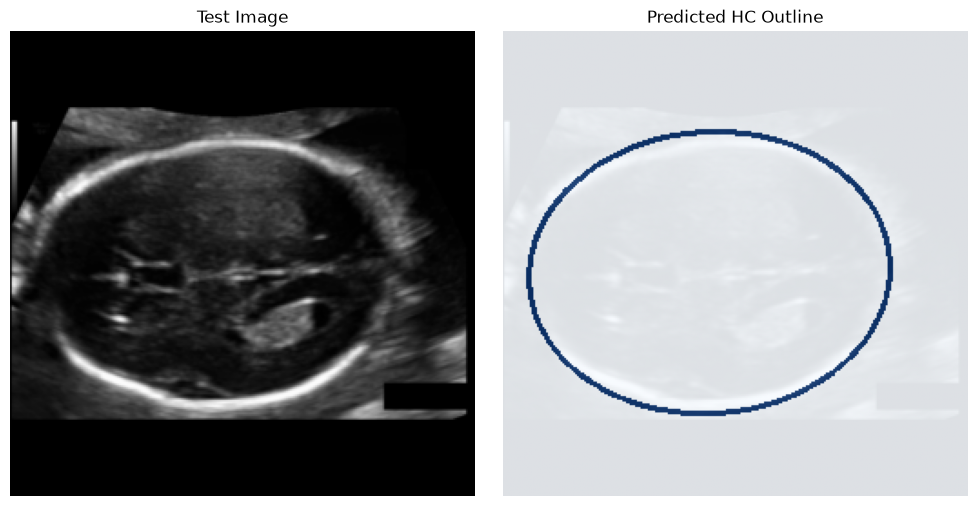

In [21]:
show_test_prediction(model, "test_set/4_HC.png")


In [22]:
import os
import cv2
import math
import numpy as np
import pandas as pd
import torch
from PIL import Image

resize_with_pad = ResizeWithPad(256)

# ---------- mask cleanup ----------
def clean_mask(mask):
    mask = (mask > 0).astype(np.uint8)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask, 8)

    if num_labels <= 1:
        return None

    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    clean = (labels == largest_label).astype(np.uint8)

    return clean


# ---------- ellipse HC ----------
def hc_from_mask(mask):
    mask = mask.astype(np.uint8) * 255

    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE
    )

    if len(contours) == 0:
        return None

    cnt = max(contours, key=cv2.contourArea)

    if len(cnt) < 5:
        return None

    ellipse = cv2.fitEllipse(cnt)
    (_, _), (MA, ma), _ = ellipse

    return math.pi * (MA + ma) / 2


# ---------- compute HC ----------
model.eval()

df = pd.read_csv("test_set_pixel_size.csv")

hc_results = []

with torch.no_grad():
    for _, row in df.iterrows():

        filename = row["filename"]
        pixel_size = row["pixel size(mm)"]

        img_path = os.path.join("test_set", filename)

        img = Image.open(img_path).convert("RGB")
        img_np = np.array(img)

        # resize + pad
        img_resized = resize_with_pad(img_np)

        # 🔥 convert PIL -> numpy
        img_resized = np.array(img_resized)

        # numpy -> tensor
        img_tensor = torch.from_numpy(img_resized)\
                          .permute(2,0,1)\
                          .float()/255.0

        pred = model(img_tensor.unsqueeze(0).to(DEVICE))
        pred_mask = torch.sigmoid(pred)[0,0] > 0.5
        pred_mask = pred_mask.cpu().numpy()

        pred_mask = clean_mask(pred_mask)

        if pred_mask is None:
            hc_results.append(np.nan)
            continue

        hc_pixels = hc_from_mask(pred_mask)

        if hc_pixels is None:
            hc_results.append(np.nan)
            continue

        hc_mm = hc_pixels * pixel_size
        hc_results.append(hc_mm)


df["head circumference (mm)"] = hc_results
df.to_csv("test_set_pixel_size_and_HC.csv", index=False)

print("Saved: test_set_pixel_size_and_HC.csv")


Saved: test_set_pixel_size_and_HC.csv


In [23]:
import os
import cv2
import math
import numpy as np
import pandas as pd
import torch
from PIL import Image

resize_with_pad = ResizeWithPad(256)

SAVE_DIR = "test_set_pred_masks"
os.makedirs(SAVE_DIR, exist_ok=True)

# ---------- cleanup (use canonical) ----------
def clean_mask(mask):
    return canonical_clean_mask(mask)


# ---------- ellipse + HC (use canonical) ----------
def ellipse_and_hc(mask):
    ellipse = canonical_mask_to_ellipse(mask)
    if ellipse is None:
        return None, None
    return ellipse, canonical_hc_from_ellipse(ellipse)


# ---------- inference ----------
model.eval()

df = pd.read_csv("test_set_pixel_size.csv")

hc_results = []

with torch.no_grad():
    for _, row in df.iterrows():

        filename = row["filename"]
        pixel_size = row["pixel size(mm)"]

        img_path = os.path.join("test_set", filename)

        img = Image.open(img_path).convert("RGB")
        img_np = np.array(img)

        img_resized = resize_with_pad(img_np)
        img_resized = np.array(img_resized)

        img_tensor = torch.from_numpy(img_resized)\
                          .permute(2,0,1)\
                          .float()/255.0

        pred = model(img_tensor.unsqueeze(0).to(DEVICE))
        pred_mask = torch.sigmoid(pred)[0,0] > 0.5
        pred_mask = pred_mask.cpu().numpy()

        pred_mask = clean_mask(pred_mask)

        if pred_mask is None:
            hc_results.append(np.nan)
            continue

        ellipse, hc_pixels = ellipse_and_hc(pred_mask)

        if ellipse is None:
            hc_results.append(np.nan)
            continue

        # ---------- save ellipse mask ----------
        H, W = pred_mask.shape
        ellipse_mask = np.zeros((H, W), dtype=np.uint8)

        # thin white ellipse
        cv2.ellipse(ellipse_mask, ellipse, 255, thickness=2)

        save_path = os.path.join(SAVE_DIR, filename)
        cv2.imwrite(save_path, ellipse_mask)

        # HC in mm
        hc_mm = hc_pixels * pixel_size
        hc_results.append(hc_mm)


df["head circumference (mm)"] = hc_results
df.to_csv("test_set_pixel_size_and_HC.csv", index=False)

print("Masks saved to:", SAVE_DIR)
print("CSV saved: test_set_pixel_size_and_HC.csv")


Masks saved to: test_set_pred_masks
CSV saved: test_set_pixel_size_and_HC.csv


---
# Model comparison: Standard U-Net vs Attention U-Net vs Swin-UNet
Cells below are all **[ADDED]**. Run order: the original cells (training cell and checkpoint-load cell for Swin-UNet), then each cell below top to bottom.
Nothing below contains stored results; every number is computed when you run the cell.

In [24]:
# [ADDED] ===== Comparison config, guards, leakage checks =====
import copy, time, json, platform, random

SEED = 42                                   # same value as the dataset-split seed; used for the two baselines
RESULTS_DIR = "comparison_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

MODEL_NAMES = ["Swin-UNet", "Standard U-Net", "Attention U-Net"]
CKPT = {
    "Swin-UNet":       "best_model.pth",                                  # written by the ORIGINAL training cell
    "Standard U-Net":  os.path.join(RESULTS_DIR, "best_standard_unet.pth"),
    "Attention U-Net": os.path.join(RESULTS_DIR, "best_attention_unet.pth"),
}
HISTORY = {}      # model name -> list of per-epoch dicts, filled ONLY by training done in this session
THRESH = best_t   # probability threshold for HC masks; identical for all models (same as original HC-evaluation cell)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# ---- data-leakage guards (the original split is NOT changed; this only checks and reports) ----
assert set(train_idx).isdisjoint(set(val_idx)), "train/val index overlap!"
assert len(train_idx) + len(val_idx) == len(full_df), "split does not cover the dataset exactly once"
assert set(train_ds.df["filename"]).isdisjoint(set(val_ds.df["filename"])), "same image file in train and val!"
_pid = lambda fn: str(fn).split("_")[0]
_shared = {_pid(f) for f in train_ds.df["filename"]} & {_pid(f) for f in val_ds.df["filename"]}
print(f"Train images: {len(train_ds)} | Val images: {len(val_ds)} | image-level overlap: 0")
if _shared:
    print(f"WARNING: {len(_shared)} patient-ID prefixes appear in BOTH train and val (split is image-level, not patient-level).")
    print("         The original split is preserved as required, so absolute scores for ALL models may be optimistic;")
    print("         the comparison between models is still like-for-like.")
print("Reminder: the val set is used for checkpoint selection (best val Dice) AND for the final numbers below, for every model.")
print("Training budget per model: EPOCHS =", EPOCHS, "| BATCH_SIZE =", BATCH_SIZE, "| LR =", LR, "| device =", DEVICE)

Train images: 799 | Val images: 200 | image-level overlap: 0
Reminder: the val set is used for checkpoint selection (best val Dice) AND for the final numbers below, for every model.
Training budget per model: EPOCHS = 15 | BATCH_SIZE = 4 | LR = 5e-05 | device = cuda


In [25]:
# [ADDED] ===== Standard U-Net and Attention U-Net (independent of SwinUNet; reuse the existing ConvBlock) =====
class StandardUNet(nn.Module):
    """Classic U-Net: 4 down-steps, 4 up-steps, channels 64-128-256-512-1024, 1-channel logit output at IMG_SIZE."""
    def __init__(self, in_ch=3, base=64):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.pool = nn.MaxPool2d(2)
        self.enc1, self.enc2 = ConvBlock(in_ch, c[0]), ConvBlock(c[0], c[1])
        self.enc3, self.enc4 = ConvBlock(c[1], c[2]), ConvBlock(c[2], c[3])
        self.bottleneck = ConvBlock(c[3], c[4])
        self.up4, self.dec4 = nn.ConvTranspose2d(c[4], c[3], 2, 2), ConvBlock(c[3] * 2, c[3])
        self.up3, self.dec3 = nn.ConvTranspose2d(c[3], c[2], 2, 2), ConvBlock(c[2] * 2, c[2])
        self.up2, self.dec2 = nn.ConvTranspose2d(c[2], c[1], 2, 2), ConvBlock(c[1] * 2, c[1])
        self.up1, self.dec1 = nn.ConvTranspose2d(c[1], c[0], 2, 2), ConvBlock(c[0] * 2, c[0])
        self.head = nn.Conv2d(c[0], 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], 1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], 1))
        return self.head(d1)


class AttentionGate(nn.Module):
    """Additive attention gate (Oktay et al., 2018). g = upsampled decoder feature, x = encoder skip (same H, W)."""
    def __init__(self, f_g, f_l, f_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(f_g, f_int, 1), nn.BatchNorm2d(f_int))
        self.W_x = nn.Sequential(nn.Conv2d(f_l, f_int, 1), nn.BatchNorm2d(f_int))
        self.psi = nn.Sequential(nn.Conv2d(f_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        return x * self.psi(self.relu(self.W_g(g) + self.W_x(x)))


class AttentionUNet(nn.Module):
    """Same backbone widths as StandardUNet, with an attention gate on every skip connection."""
    def __init__(self, in_ch=3, base=64):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.pool = nn.MaxPool2d(2)
        self.enc1, self.enc2 = ConvBlock(in_ch, c[0]), ConvBlock(c[0], c[1])
        self.enc3, self.enc4 = ConvBlock(c[1], c[2]), ConvBlock(c[2], c[3])
        self.bottleneck = ConvBlock(c[3], c[4])
        self.up4, self.att4, self.dec4 = nn.ConvTranspose2d(c[4], c[3], 2, 2), AttentionGate(c[3], c[3], c[3] // 2), ConvBlock(c[3] * 2, c[3])
        self.up3, self.att3, self.dec3 = nn.ConvTranspose2d(c[3], c[2], 2, 2), AttentionGate(c[2], c[2], c[2] // 2), ConvBlock(c[2] * 2, c[2])
        self.up2, self.att2, self.dec2 = nn.ConvTranspose2d(c[2], c[1], 2, 2), AttentionGate(c[1], c[1], c[1] // 2), ConvBlock(c[1] * 2, c[1])
        self.up1, self.att1, self.dec1 = nn.ConvTranspose2d(c[1], c[0], 2, 2), AttentionGate(c[0], c[0], c[0] // 2), ConvBlock(c[0] * 2, c[0])
        self.head = nn.Conv2d(c[0], 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        g4 = self.up4(b);  d4 = self.dec4(torch.cat([g4, self.att4(g4, e4)], 1))
        g3 = self.up3(d4); d3 = self.dec3(torch.cat([g3, self.att3(g3, e3)], 1))
        g2 = self.up2(d3); d2 = self.dec2(torch.cat([g2, self.att2(g2, e2)], 1))
        g1 = self.up1(d2); d1 = self.dec1(torch.cat([g1, self.att1(g1, e1)], 1))
        return self.head(d1)


def count_params(m):
    return sum(p.numel() for p in m.parameters())

for _cls in (StandardUNet, AttentionUNet):
    _m = _cls()
    _out = _m(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE))
    assert _out.shape == (2, 1, IMG_SIZE, IMG_SIZE), _out.shape
    print(f"{_cls.__name__}: {count_params(_m)/1e6:.2f} M params, output {tuple(_out.shape)}")
    del _m, _out

StandardUNet: 31.04 M params, output (2, 1, 256, 256)
AttentionUNet: 31.40 M params, output (2, 1, 256, 256)


In [26]:
# [ADDED] ===== Shared training routine for the two baselines (mirrors the ORIGINAL Swin-UNet training cell) =====
# Identical to the original: loss = 0.3*BCE + 0.5*Dice + 0.2*boundary (same functions), Adam(lr=LR),
# ReduceLROnPlateau(mode="max", factor=0.5, patience=2, min_lr=1e-6) stepped on val Dice, best-val-Dice checkpoint
# (saved when strictly greater), same train_loader / val_loader, same EPOCHS, same per-epoch metric definitions.
# Differences: (1) no encoder freeze (the U-Nets have no pretrained encoder); (2) `verbose=True` omitted from the scheduler
# (deprecated in PyTorch, already warned in your saved output; LR is printed every epoch instead).
def combined_loss(pred, mask):
    return 0.3 * bce(pred, mask) + 0.5 * dice_loss(pred, mask) + 0.2 * boundary_loss(pred, mask)

def train_baseline(name, net, ckpt_path):
    net = net.to(DEVICE)
    opt_b = torch.optim.Adam(net.parameters(), lr=LR)                      # separate optimiser
    sched_b = torch.optim.lr_scheduler.ReduceLROnPlateau(opt_b, mode="max", factor=0.5, patience=2, min_lr=1e-6)
    if os.path.exists(ckpt_path):
        os.remove(ckpt_path)                                               # never let a stale checkpoint pass as a new result
    best_dice_b, hist = 0, []
    set_seed(SEED)                                                         # same shuffle/augmentation RNG stream for each baseline
    for epoch in range(EPOCHS):
        t0 = time.time()
        net.train()
        tl = []
        for img, mask, *_ in train_loader:
            img, mask = img.to(DEVICE), mask.to(DEVICE)
            pred = net(img)
            loss = combined_loss(pred, mask)
            opt_b.zero_grad(); loss.backward(); opt_b.step()
            tl.append(loss.item())
        train_loss = np.mean(tl)

        net.eval()
        vl, dices, ious = [], [], []
        with torch.no_grad():
            for img, mask, *_ in val_loader:
                img, mask = img.to(DEVICE), mask.to(DEVICE)
                pred = net(img)
                vl.append(combined_loss(pred, mask).item())
                dices.append(dice_metric(pred, mask).item())
                ious.append(iou_metric(pred, mask).item())
        val_loss, mean_dice, mean_iou = np.mean(vl), np.mean(dices), np.mean(ious)

        sched_b.step(mean_dice)
        if mean_dice > best_dice_b:
            best_dice_b = mean_dice
            torch.save(net.state_dict(), ckpt_path)
            print("✅ Saved best", name)
        lr_now = opt_b.param_groups[0]["lr"]
        print(f"[{name}] Epoch {epoch+1:02d} | LR {lr_now:.1e} | Train Loss {train_loss:.4f} | "
              f"Val Loss {val_loss:.4f} | Dice {mean_dice:.4f} | IoU {mean_iou:.4f}")
        hist.append(dict(epoch=epoch + 1, lr=lr_now, train_loss=float(train_loss), val_loss=float(val_loss),
                         val_dice=float(mean_dice), val_iou=float(mean_iou), best_so_far=float(best_dice_b),
                         epoch_seconds=time.time() - t0))
    with open(os.path.join(RESULTS_DIR, f"history_{name.replace(' ', '_').lower()}.json"), "w") as f:
        json.dump(hist, f, indent=1)
    return hist

In [27]:
# [ADDED] Train Standard U-Net (own optimiser / scheduler / checkpoint / history)
set_seed(SEED)
_net = StandardUNet()
print(f"Standard U-Net: {count_params(_net)/1e6:.2f} M params")
HISTORY["Standard U-Net"] = train_baseline("Standard U-Net", _net, CKPT["Standard U-Net"])
del _net
if torch.cuda.is_available(): torch.cuda.empty_cache()

Standard U-Net: 31.04 M params
✅ Saved best Standard U-Net
[Standard U-Net] Epoch 01 | LR 5.0e-05 | Train Loss 0.4572 | Val Loss 0.2914 | Dice 0.9181 | IoU 0.8547
[Standard U-Net] Epoch 02 | LR 5.0e-05 | Train Loss 0.2640 | Val Loss 0.2397 | Dice 0.9101 | IoU 0.8410
✅ Saved best Standard U-Net
[Standard U-Net] Epoch 03 | LR 5.0e-05 | Train Loss 0.2164 | Val Loss 0.1943 | Dice 0.9404 | IoU 0.8911
✅ Saved best Standard U-Net
[Standard U-Net] Epoch 04 | LR 5.0e-05 | Train Loss 0.1801 | Val Loss 0.1690 | Dice 0.9522 | IoU 0.9123
✅ Saved best Standard U-Net
[Standard U-Net] Epoch 05 | LR 5.0e-05 | Train Loss 0.1605 | Val Loss 0.1600 | Dice 0.9531 | IoU 0.9142
✅ Saved best Standard U-Net
[Standard U-Net] Epoch 06 | LR 5.0e-05 | Train Loss 0.1510 | Val Loss 0.1316 | Dice 0.9586 | IoU 0.9235
[Standard U-Net] Epoch 07 | LR 5.0e-05 | Train Loss 0.1347 | Val Loss 0.1226 | Dice 0.9550 | IoU 0.9172
[Standard U-Net] Epoch 08 | LR 5.0e-05 | Train Loss 0.1243 | Val Loss 0.1154 | Dice 0.9566 | IoU 0.91

In [ ]:
# [ADDED] Train Attention U-Net (own optimiser / scheduler / checkpoint / history)
set_seed(SEED)
_net = AttentionUNet()
print(f"Attention U-Net: {count_params(_net)/1e6:.2f} M params")
HISTORY["Attention U-Net"] = train_baseline("Attention U-Net", _net, CKPT["Attention U-Net"])
del _net
if torch.cuda.is_available(): torch.cuda.empty_cache()

Attention U-Net: 31.40 M params
✅ Saved best Attention U-Net
[Attention U-Net] Epoch 01 | LR 5.0e-05 | Train Loss 0.4355 | Val Loss 0.2682 | Dice 0.9252 | IoU 0.8661
✅ Saved best Attention U-Net
[Attention U-Net] Epoch 02 | LR 5.0e-05 | Train Loss 0.2439 | Val Loss 0.2162 | Dice 0.9297 | IoU 0.8729
✅ Saved best Attention U-Net
[Attention U-Net] Epoch 03 | LR 5.0e-05 | Train Loss 0.1977 | Val Loss 0.1789 | Dice 0.9478 | IoU 0.9047
✅ Saved best Attention U-Net
[Attention U-Net] Epoch 04 | LR 5.0e-05 | Train Loss 0.1725 | Val Loss 0.1718 | Dice 0.9484 | IoU 0.9062


In [ ]:
# [ADDED] ===== Common evaluation: same val samples, same metric definitions, for every model =====
# Dice/IoU : dice_metric / iou_metric from the original notebook, averaged over val batches (as in the training log),
#            plus per-image means as a supplementary figure.  Threshold 0.5 (inside those functions).
# HC (px)  : EXACT procedure and helper definitions of the original HC-evaluation cell (clean_mask -> fitEllipse ->
#            pi*(MA+ma)/2), pred mask thresholded at THRESH vs HC of the GT-mask ellipse, both in the 256x256 network
#            space.  NOTE the val images are resized to 256x256 WITHOUT padding (anisotropic stretch), so these "pixels"
#            are NOT physical units and cannot be converted to mm by multiplying with pixel size.
# HC (mm)  : ADDED. Predicted probability map is resized back to the original image size, same threshold/cleanup/ellipse/
#            formula, x "pixel size(mm)" from the CSV, compared with the CSV "head circumference (mm)".
# The helpers below are frozen copies of the original HC-evaluation cell's definitions, because later original cells
# re-define the names clean_mask / mask_to_ellipse / hc_from_ellipse with different behaviour.
def _cmp_clean_mask(mask):
    mask = (mask > 0).astype(np.uint8)
    mask = cv2.GaussianBlur(mask * 255, (7, 7), 0)
    _, mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
    mask = mask // 255
    n_lab, labels, stats, _ = cv2.connectedComponentsWithStats(mask, 8)
    if n_lab <= 1:
        return None
    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    clean = (labels == largest).astype(np.uint8)
    contours, _ = cv2.findContours(clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(clean)
    cv2.drawContours(filled, contours, -1, 1, thickness=-1)
    return filled

def _cmp_mask_to_ellipse(mask):
    mask = mask.astype(np.uint8) * 255
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if len(contours) == 0:
        return None
    cnt = max(contours, key=cv2.contourArea)
    if len(cnt) < 5:
        return None
    return cv2.fitEllipse(cnt)

def _cmp_hc_from_ellipse(ellipse):
    (_, _), (MA, ma), _ = ellipse
    return math.pi * (MA + ma) / 2

def _cmp_hc(mask_bool):
    m = _cmp_clean_mask(mask_bool)
    if m is None:
        return None
    e = _cmp_mask_to_ellipse(m)
    return None if e is None else _cmp_hc_from_ellipse(e)

_NAN = float("nan")
_val_meta = val_ds.df.reset_index(drop=True)
_orig_wh = [Image.open(os.path.join(val_ds.img_dir, fn)).size for fn in _val_meta["filename"]]   # (W, H) of original images

# cache the val images once (deterministic val_aug) for the batch-size-1 timing pass
_VAL_IMGS = torch.cat([img for img, *_ in val_loader], 0)
assert len(_VAL_IMGS) == len(val_ds) == len(_orig_wh)

def load_model_for_eval(name):
    """Returns (net, None) or (None, reason). Never falls back to checkpoints from earlier sessions."""
    if name == "Swin-UNet":
        if not ("swin_history" in globals() and len(swin_history) == EPOCHS):
            return None, "Swin-UNet training cell has not completed in this session (swin_history missing/incomplete)"
        if not os.path.exists(CKPT[name]):
            return None, f"checkpoint {CKPT[name]} not found"
        net = copy.deepcopy(model)                      # the original SwinUNet instance; weights replaced by best checkpoint
    else:
        if name not in HISTORY or len(HISTORY[name]) != EPOCHS:
            return None, "not trained in this session"
        if not os.path.exists(CKPT[name]):
            return None, f"checkpoint {CKPT[name]} not found"
        net = StandardUNet() if name == "Standard U-Net" else AttentionUNet()
    net.load_state_dict(torch.load(CKPT[name], map_location=DEVICE))
    return net.to(DEVICE).eval(), None

@torch.no_grad()
def evaluate_model(name, net):
    batch_d, batch_i, rows, i0 = [], [], [], 0
    for img, mask, *_ in val_loader:
        img, mask = img.to(DEVICE), mask.to(DEVICE)
        logits = net(img)
        batch_d.append(dice_metric(logits, mask).item())
        batch_i.append(iou_metric(logits, mask).item())
        prob = torch.sigmoid(logits)
        hard = (prob > 0.5).float()
        for b in range(img.shape[0]):
            idx = i0 + b
            inter = (hard[b] * mask[b]).sum()
            d_img = ((2 * inter + 1e-5) / (hard[b].sum() + mask[b].sum() + 1e-5)).item()
            i_img = ((inter + 1e-5) / (hard[b].sum() + mask[b].sum() - inter + 1e-5)).item()
            p = prob[b, 0].cpu().numpy()
            # ---- HC in 256x256 network pixels (original procedure) ----
            hp, hg = _cmp_hc(p > THRESH), _cmp_hc((mask[b, 0] > 0.5).cpu().numpy())
            ok_px = hp is not None and hg is not None
            # ---- HC in mm (added) ----
            W0, H0 = _orig_wh[idx]
            hp_full = _cmp_hc(cv2.resize(p, (W0, H0), interpolation=cv2.INTER_LINEAR) > THRESH)
            ps = float(_val_meta.loc[idx, "pixel size(mm)"])
            ok_mm = hp_full is not None
            rows.append(dict(model=name, val_idx=idx, filename=_val_meta.loc[idx, "filename"],
                             dice_img=d_img, iou_img=i_img,
                             hc_pred_px256=hp if ok_px else _NAN, hc_gt_px256=hg if ok_px else _NAN, valid_px=ok_px,
                             hc_pred_mm=hp_full * ps if ok_mm else _NAN,
                             hc_gt_mm=float(_val_meta.loc[idx, "head circumference (mm)"]), valid_mm=ok_mm))
        i0 += img.shape[0]
    return float(np.mean(batch_d)), float(np.mean(batch_i)), rows

@torch.no_grad()
def time_inference(net, n_warmup=10):
    """Forward pass only, batch size 1, fp32, data already on device; mean/std/median ms per image over the whole val set."""
    sync = (lambda: torch.cuda.synchronize()) if DEVICE == "cuda" else (lambda: None)
    for _ in range(n_warmup):
        net(_VAL_IMGS[:1].to(DEVICE))
    sync()
    ts = []
    for k in range(len(_VAL_IMGS)):
        x = _VAL_IMGS[k:k + 1].to(DEVICE); sync()
        t0 = time.perf_counter(); net(x); sync()
        ts.append((time.perf_counter() - t0) * 1e3)
    return float(np.mean(ts)), float(np.std(ts)), float(np.median(ts))

EVAL, PER_SAMPLE, PENDING = {}, [], {}
for _name in MODEL_NAMES:
    _net, _why = load_model_for_eval(_name)
    if _net is None:
        PENDING[_name] = _why
        print(f"PENDING  {_name}: {_why}")
        continue
    _d, _i, _rows = evaluate_model(_name, _net)
    _ms, _ms_sd, _ms_med = time_inference(_net)
    EVAL[_name] = dict(dice_batch=_d, iou_batch=_i, params_M=count_params(_net) / 1e6,
                       ms_mean=_ms, ms_std=_ms_sd, ms_median=_ms_med)
    PER_SAMPLE += _rows
    print(f"Evaluated {_name}: Dice {_d:.4f} | IoU {_i:.4f} | {_ms:.2f} ms/img (bs=1, {DEVICE})")
    del _net
    if torch.cuda.is_available(): torch.cuda.empty_cache()

In [ ]:
# [ADDED] ===== Final comparison table + CSV export =====
def _rmse(a): return float(np.sqrt(np.mean(np.square(a))))

ps_df = pd.DataFrame(PER_SAMPLE)
evaluated = list(EVAL)
common_px = common_mm = set()
if evaluated:
    common_px = set.intersection(*[set(ps_df[(ps_df.model == m) & ps_df.valid_px].val_idx) for m in evaluated])
    common_mm = set.intersection(*[set(ps_df[(ps_df.model == m) & ps_df.valid_mm].val_idx) for m in evaluated])

rows = []
for m in MODEL_NAMES:
    if m not in EVAL:
        rows.append(dict(Model=m, Status=f"PENDING ({PENDING.get(m, 'not run')})"))
        continue
    d = ps_df[ps_df.model == m]
    c_px, c_mm = d[d.val_idx.isin(common_px)], d[d.val_idx.isin(common_mm)]
    o_px, o_mm = d[d.valid_px], d[d.valid_mm]
    e_px, e_mm = (c_px.hc_pred_px256 - c_px.hc_gt_px256), (c_mm.hc_pred_mm - c_mm.hc_gt_mm)
    eo_px, eo_mm = (o_px.hc_pred_px256 - o_px.hc_gt_px256), (o_mm.hc_pred_mm - o_mm.hc_gt_mm)
    best_ep = int(np.argmax([h["val_dice"] for h in (swin_history if m == "Swin-UNet" else HISTORY[m])])) + 1
    rows.append({
        "Model": m,
        "Status": "COMPLETE" if len(evaluated) == len(MODEL_NAMES) else "PARTIAL (common sample set covers evaluated models only)",
        "Params (M)": EVAL[m]["params_M"],
        "Best epoch": best_ep,
        "Val Dice (batch-mean, original definition)": EVAL[m]["dice_batch"],
        "Val IoU (batch-mean, original definition)": EVAL[m]["iou_batch"],
        "Val Dice (per-image mean)": d.dice_img.mean(),
        "Val IoU (per-image mean)": d.iou_img.mean(),
        "HC MAE [px, 256x256 space]": float(e_px.abs().mean()),
        "HC RMSE [px, 256x256 space]": _rmse(e_px),
        "HC MAE [mm]": float(e_mm.abs().mean()),
        "HC RMSE [mm]": _rmse(e_mm),
        "Inference [ms/img, bs=1, fwd only]": EVAL[m]["ms_mean"],
        "Inference std [ms]": EVAL[m]["ms_std"],
        "N val images": len(d),
        "N common samples (px metrics)": len(c_px),
        "N common samples (mm metrics)": len(c_mm),
        # supplementary: each model on ITS OWN valid samples (this is what the original cell reports)
        "HC MAE [px] own-valid": float(eo_px.abs().mean()), "HC RMSE [px] own-valid": _rmse(eo_px), "N own-valid (px)": len(o_px),
        "HC MAE [mm] own-valid": float(eo_mm.abs().mean()), "HC RMSE [mm] own-valid": _rmse(eo_mm), "N own-valid (mm)": len(o_mm),
        "Device": (torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU"),
    })
summary = pd.DataFrame(rows)
summary_out = summary.astype(object).where(summary.notna(), "PENDING")      # pending cells are labelled, never blank/zero

summary_out.to_csv(os.path.join(RESULTS_DIR, "comparison_summary.csv"), index=False)
ps_df.to_csv(os.path.join(RESULTS_DIR, "comparison_per_sample.csv"), index=False)
_hist_rows = []
for m in MODEL_NAMES:
    h = swin_history if (m == "Swin-UNet" and "swin_history" in globals() and len(swin_history) == EPOCHS) else HISTORY.get(m)
    if h and len(h) == EPOCHS:
        _hist_rows += [dict(model=m, **r) for r in h]
pd.DataFrame(_hist_rows).to_csv(os.path.join(RESULTS_DIR, "comparison_training_history.csv"), index=False)
with open(os.path.join(RESULTS_DIR, "comparison_run_info.json"), "w") as f:
    json.dump(dict(seed=SEED, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, img_size=IMG_SIZE, hc_threshold=THRESH,
                   device=DEVICE, gpu=(torch.cuda.get_device_name(0) if DEVICE == "cuda" else None),
                   torch=torch.__version__, python=platform.python_version(),
                   n_train=len(train_ds), n_val=len(val_ds), pending=PENDING), f, indent=1)

print("Units: Dice/IoU unitless | 'px' = pixels of the 256x256 network input (stretched, NOT physical) | 'mm' = millimetres | time in ms")
print("Common-sample metrics use the same val images for every model (images where any model failed ellipse fitting are excluded).")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 50)
display_cols = ["Model", "Status", "Params (M)", "Best epoch", "Val Dice (batch-mean, original definition)",
                "Val IoU (batch-mean, original definition)", "HC MAE [px, 256x256 space]", "HC RMSE [px, 256x256 space]",
                "HC MAE [mm]", "HC RMSE [mm]", "Inference [ms/img, bs=1, fwd only]", "N common samples (px metrics)",
                "N common samples (mm metrics)"]
_show = summary_out[[c for c in display_cols if c in summary_out.columns]]
try:
    from IPython.display import display
    display(_show.style.format(precision=4).hide(axis="index"))
except Exception:
    print(_show.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\nSaved to ./" + RESULTS_DIR + ": comparison_summary.csv, comparison_per_sample.csv, comparison_training_history.csv, comparison_run_info.json")

In [ ]:
# [ADDED] ===== Plots: training/validation loss, validation Dice/IoU, model-wise metrics =====
COLORS = {"Swin-UNet": "tab:blue", "Standard U-Net": "tab:orange", "Attention U-Net": "tab:green"}
hist_df = pd.read_csv(os.path.join(RESULTS_DIR, "comparison_training_history.csv")) if os.path.getsize(
    os.path.join(RESULTS_DIR, "comparison_training_history.csv")) > 2 else pd.DataFrame()

if hist_df.empty:
    print("PENDING: no completed training histories available, so training curves cannot be drawn.")
else:
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for m, g in hist_df.groupby("model"):
        ax[0].plot(g.epoch, g.train_loss, "--", color=COLORS[m], label=f"{m} train")
        ax[0].plot(g.epoch, g.val_loss, "-", color=COLORS[m], label=f"{m} val")
    ax[0].set_title("Training / validation loss (combined loss, unitless)"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend(fontsize=8)
    for m, g in hist_df.groupby("model"):
        ax[1].plot(g.epoch, g.val_loss, color=COLORS[m], label=m)
    ax[1].set_title("Validation loss only"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss"); ax[1].legend()
    plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "plot_loss.png"), dpi=150); plt.show()

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for m, g in hist_df.groupby("model"):
        ax[0].plot(g.epoch, g.val_dice, color=COLORS[m], label=m)
        ax[1].plot(g.epoch, g.val_iou, color=COLORS[m], label=m)
    ax[0].set_title("Validation Dice per epoch"); ax[1].set_title("Validation IoU per epoch")
    for a, lab in zip(ax, ["Dice", "IoU"]):
        a.set_xlabel("Epoch"); a.set_ylabel(lab); a.legend()
    plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "plot_val_dice_iou.png"), dpi=150); plt.show()

done = summary[summary["Status"].astype(str).str.startswith(("COMPLETE", "PARTIAL"))]
if done.empty:
    print("PENDING: no evaluated models, so model-wise metric bars cannot be drawn.")
else:
    panels = [("Val Dice (batch-mean, original definition)", "Dice (unitless)"),
              ("Val IoU (batch-mean, original definition)", "IoU (unitless)"),
              ("HC MAE [px, 256x256 space]", "HC MAE (px, 256x256 space)"),
              ("HC RMSE [px, 256x256 space]", "HC RMSE (px, 256x256 space)"),
              ("HC MAE [mm]", "HC MAE (mm)"),
              ("HC RMSE [mm]", "HC RMSE (mm)"),
              ("Inference [ms/img, bs=1, fwd only]", "Inference (ms / image)")]
    fig, axes = plt.subplots(2, 4, figsize=(18, 7)); axes = axes.ravel()
    for a, (col, lab) in zip(axes, panels):
        a.bar(done["Model"], done[col].astype(float), color=[COLORS[m] for m in done["Model"]])
        a.set_title(lab, fontsize=10); a.tick_params(axis="x", rotation=20)
        for x, v in enumerate(done[col].astype(float)):
            a.text(x, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    axes[-1].axis("off")
    plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "plot_model_metrics.png"), dpi=150); plt.show()

### Notes, assumptions and caveats (read before quoting results)
**What was added vs. left alone.** The original Swin-UNet class, loss, preprocessing, augmentation, split, post-processing and HC functions are unchanged. All other original cells (including the test-set inference cells) are untouched and still run on the Swin-UNet `model`.

**Things to be aware of (not changed, because changing them would alter the experiment):**
1. **Patient-level leakage risk.** The split is image-level (`RandomState(42)` over CSV rows). HC18 contains several frames per patient; the config cell reports how many patient-ID prefixes occur in both train and val. The split was preserved as required, but if the count is non-zero all absolute scores are probably optimistic (the model comparison remains like-for-like).
2. **Validation set is used twice** for every model: best-checkpoint selection (and the LR scheduler) and the final reported numbers. There is no separate labelled test set in this notebook (the test set has no masks/HC), so reported scores are validation scores.
3. **Pixel HC is in stretched 256×256 space.** Val images are resized to 256×256 without padding, so px-HC is a relative quantity. The mm columns resize the predicted probability map back to the original resolution first, use the CSV pixel size, and compare against the CSV head-circumference. This mm evaluation is an addition; the px columns reproduce the original evaluation procedure.
4. **Several original cells redefine `clean_mask`, `mask_to_ellipse`, `hc_from_ellipse`** with different behaviour (e.g. the first uses the Ramanujan perimeter formula, the HC-evaluation cell uses π(MA+ma)/2). The comparison uses frozen copies of the HC-evaluation cell's versions, so results do not depend on cell run order.
5. **The original test-inference cells** feed images scaled to [0,1] *without* the ImageNet mean/std normalisation used in training, and use pad-resize while training/validation use stretch-resize. This does not affect the comparison (which uses `val_loader`), but test-set HC predictions from those cells may be affected. Left unchanged.
6. **Pretrained vs. from-scratch.** Swin-UNet starts from ImageNet-pretrained weights; both U-Nets start from random initialisation. With the shared `LR = 5e-5` and 15 epochs, the U-Nets may be under-trained relative to what they could reach with their own tuned hyper-parameters. That is a consequence of the "same training budget" rule, not a tuned result.
7. **Seeding.** The baselines are seeded (`SEED = 42`) before initialisation and again before training. The original Swin-UNet cell was not seeded and was left that way, so its run is not bit-reproducible. Results of a single run per model; no confidence intervals.
8. **HC failure handling.** As in the original cell, an image is skipped if cleanup/ellipse fitting fails. Headline HC metrics use the images valid for *all* models; the `own-valid` columns in the CSV show each model on its own valid set.
9. **Inference time** is forward-pass only, batch size 1, fp32, on the device shown in the table (after 10 warm-up passes). Numbers from CPU and GPU, or from different GPUs, are not comparable.